# 04 · Reranker (learning-to-rank)

**Objetivo:** treinar e avaliar um reranker próprio, um modelo de machine learning que reordena os 100 primeiros candidatos de um retrieval combinando features de texto e features numéricas do produto, seguindo o protocolo de [docs/EVALUATION.md](../docs/EVALUATION.md), seção "Reranker (learning-to-rank)". O reranker é treinado sobre os candidatos de dois retrievals de `03_semantic_hybrid.ipynb`: a BM25 v2 e a hybrid search.

**Regras deste notebook**
- **O test set não é usado:** nem os `label`, nem o texto das queries do test set. Ele roda uma única vez, depois da seleção registrada, em `06_test_set.ipynb`.
- **As escolhas usam só o train set,** com GroupKFold (Etapa 3). O reranker aprende com os `label`, então o tuning não pode medir nas mesmas queries em que treina.
- **O validation set roda uma única vez** por sistema e por ablation, sem novo tuning (Etapas 4 a 6).
- Todas as decisões foram registradas no `docs/EVALUATION.md` antes dos números que dependem delas; as que vieram depois de algum número dizem isso.

**Como ler este notebook**
- Cada seção começa explicando a pergunta que ela responde, e pode ser lida sozinha.
- Toda tabela e todo gráfico têm um título que diz o que é medido e em quais dados.
- As conclusões ficam logo abaixo da célula que as sustenta, sempre no mesmo formato:
  - **Resultados:** o que as saídas mostram, um fato por item.
  - **O que isso implica (nossa interpretação):** leituras que não foram medidas.
  - **Suposições:** o que tomamos como verdadeiro sem verificar, e o que muda se não for.
  - **Limitações:** o que a medição não captura.
  - **Escolhas e alternativas:** cada escolha, se está decidida, proposta ou em aberto, e as outras opções.
- Os termos técnicos ficam em inglês e estão definidos na seção "Termos usados no notebook". Os termos são os mesmos de `01_eda.ipynb`, `02_bm25.ipynb` e `03_semantic_hybrid.ipynb`.

**Etapas**
1. Os candidatos e os exemplos de treino
2. As features
3. Tuning no train set (GroupKFold)
4. O reranker no validation set
5. O que cada parte do reranker agrega
6. Latência
7. Tabela final, comparação dos sistemas e seleção

## TL;DR

Resumo das conclusões do notebook. Entre parênteses, a etapa onde estão os números.

**O que fizemos.** Este notebook treina e avalia um reranker: um modelo de machine learning que recebe os 100 primeiros candidatos de um retrieval (a primeira fase da busca) e os reordena. O modelo é um LambdaMART (LightGBM), que aprende comparando pares de produtos da mesma query. Cada par (query, produto) é descrito por 30 features em cinco grupos: retrieval (score e posição na BM25 v2, na semantic search e na RRF), text (score do BM25 e fração dos tokens da query em cada field, presença do número da query e cosine similarity do short text), numeric (ratings, tamanho de `product_description` e de `product_features`, fields null), query (número de tokens e presença de número na query) e cross_encoder (nota de um modelo pré-treinado que lê a query e o produto juntos). Foram treinados um reranker sobre os candidatos da BM25 v2 e outro sobre os da hybrid search (`02_bm25.ipynb` e `03_semantic_hybrid.ipynb`). Os hiperparâmetros foram escolhidos no train set; o validation set foi usado uma única vez por sistema, para comparar e escolher o sistema que vai ao test set. O test set não foi usado.

**Como medimos.** Cada par (query, produto) julgado tem um `label`: Exact (o produto atende à query), Partial (o tipo de produto é o pedido, mas algum detalhe diverge) ou Irrelevant. Produtos não julgados para a query são contados como Irrelevant, no treino e na avaliação.
- **NDCG@10 (métrica principal):** varia de 0 a 1 e avalia os 10 primeiros resultados pela relevância de cada produto (Exact vale mais que Partial) e pela posição em que aparece. É a métrica da regra de seleção do sistema.
- **condensed NDCG@10:** o NDCG@10 calculado depois de retirar da lista os produtos sem `label`. Mede só a ordem dos produtos julgados.
- **MRR@10:** 1 dividido pela posição do primeiro Exact entre os 10 primeiros resultados (0 se não houver nenhum).
- **judged@10:** fração dos 10 primeiros resultados que têm `label`.
- **Capped Recall@100:** fração dos produtos Exact da query presentes entre os 100 primeiros resultados (o denominador é o menor entre 100 e o número de Exact da query). O reranker só reordena os 100 candidatos, então tem o mesmo Capped Recall@100 do seu retrieval. `capped_recall@100_exact_partial` é o mesmo, considerando também os Partial como relevantes.
- **Diferença "não distinguível de 0":** diferença pequena demais para ser detectada com as 97 queries do validation set (77 com algum Exact). Não significa que os dois sistemas sejam equivalentes.

### Resultados no validation set

| Métrica | BM25 v2 | BM25 v2 + reranker | hybrid search | hybrid search + reranker | escolhido: hybrid search + reranker sem o cross-encoder |
|---|---|---|---|---|---|
| NDCG@10 (principal) | 0,653 | 0,744 | 0,747 | 0,772 | 0,776 |
| condensed NDCG@10 | 0,799 | 0,802 | 0,834 | 0,832 | 0,831 |
| MRR@10 | 0,661 | 0,710 | 0,681 | 0,699 | 0,708 |
| judged@10 | 0,782 | 0,890 | 0,854 | 0,890 | 0,899 |
| Capped Recall@100 | 0,705 | 0,705 | 0,714 | 0,714 | 0,714 |
| `capped_recall@100_exact_partial` | 0,661 | 0,661 | 0,694 | 0,694 | 0,694 |
| latência do retrieval, p50 / p95 (ms) | 0,7 / 2,9 | 0,7 / 2,9 | 9,3 / 12,8 | 9,3 / 12,8 | 9,3 / 12,8 |
| latência do ranking, p50 / p95 (ms) | – | 283,0 / 418,8 | – | 312,6 / 454,5 | 24,8 / 28,9 |

Média por query nas 97 queries do validation set (77 no MRR@10 e no Capped Recall@100, que exigem algum Exact). O BM25 v2 + reranker e o hybrid search + reranker usam o cross-encoder; o BM25 v2 + reranker usa 25 features, sem as 5 que dependem do embedding model. Latência da execução salva, numa única máquina, só com CPU; o ranking não inclui o tempo do retrieval (Etapas 6 e 7.1).

| Comparação | NDCG@10 (CI 95%) | condensed NDCG@10 (CI 95%) | MRR@10 (CI 95%) | judged@10 (CI 95%) |
|---|---|---|---|---|
| BM25 v2 + reranker − BM25 v2 | +0,091 [0,059; 0,126] | +0,003 [−0,018; 0,025] | +0,049 [−0,004; 0,109] | +0,107 [0,073; 0,145] |
| hybrid search + reranker − hybrid search | +0,025 [0,009; 0,043] | −0,002 [−0,013; 0,010] | +0,018 [−0,016; 0,052] | +0,036 [0,019; 0,056] |
| hybrid search + reranker − BM25 v2 + reranker | +0,028 [0,010; 0,048] | +0,030 [0,011; 0,050] | −0,011 [−0,061; 0,036] | +0,009 [−0,009; 0,028] |
| hybrid search + reranker − escolhido (sem o cross-encoder) | −0,005 [−0,015; 0,006] | +0,001 [−0,007; 0,009] | −0,009 [−0,039; 0,021] | −0,009 [−0,021; 0,002] |
| LambdaMART − pointwise, na hybrid search | +0,032 [0,009; 0,056] | +0,036 [0,016; 0,058] | +0,024 [−0,032; 0,079] | −0,003 [−0,020; 0,014] |
| LambdaMART − pointwise, na BM25 v2 | +0,014 [−0,005; 0,033] | +0,014 [0,000; 0,028] | +0,043 [−0,015; 0,106] | −0,002 [−0,023; 0,017] |

Diferença média por query entre os dois sistemas e, entre colchetes, o intervalo de confiança de 95% do paired bootstrap (as queries são sorteadas com reposição 2.000 vezes, e a diferença é recalculada a cada sorteio). Quando o intervalo contém 0, a diferença não é distinguível de 0. Pointwise: o mesmo LightGBM, com as mesmas features, treinado para prever a nota de cada produto isoladamente, sem comparar produtos da mesma query (Etapas 4.1, 4.3, 5.1 e 5.2).

### Principais descobertas

- **O reranker aumenta o NDCG@10 dos dois retrievals.** No validation set, o NDCG@10 sobe de 0,653 para 0,744 sobre a BM25 v2 e de 0,747 para 0,772 sobre a hybrid search, as duas diferenças estatisticamente significativas. O ganho também aparece com o NDCG cortado em 5 e em 15 resultados (Etapas 4.1 e 4.2).
- **O ganho vem de levar ao topo produtos com `label`; não há melhora detectável na ordem dos produtos julgados.** O judged@10 sobe de 0,782 para 0,890 na BM25 v2 e de 0,854 para 0,890 na hybrid search, as duas diferenças significativas. O condensed NDCG@10 (0,799 e 0,802; 0,834 e 0,832) e o MRR@10 (0,661 e 0,710; 0,681 e 0,699) não mudam de forma distinguível de 0. Com 97 queries, uma melhora pequena na ordem dos produtos julgados (abaixo de cerca de 0,02) não seria detectada (Etapa 4.1).
- **O reranker aprende a rebaixar os produtos sem `label`, e é daí que vem o ganho de NDCG@10.** Cerca de 3 em cada 10 candidatos do train set não têm `label` (29,6% na BM25 v2 e 27,6% na hybrid search). Na variante escolhida (`zero`), eles entram no treino com nota 0, e cerca de dois terços dos pares de treino passam a envolver um produto sem `label`. No train set, fora do fold, a `zero` supera a variante que os retira do treino (`drop`) no NDCG@10 (+0,053 na BM25 v2 e +0,045 na hybrid search, as duas significativas), mas não no condensed NDCG@10, em que a `drop` fica à frente na BM25 v2 (−0,010, significativa) e não se distingue na hybrid search (Etapas 1.1, 1.2 e 3.2).
- **Parte do ganho é real e parte, provavelmente a maior, é efeito do pooling bias.** Um produto relevante que nunca foi julgado conta como 0, então tirá-lo do topo também aumenta o NDCG@10. Os produtos sem `label` que o reranker tira do topo têm nota mediana de −5,96 no cross-encoder, perto da dos Irrelevant (−6,25), o que indica que muitos estão fora do assunto. Mas, numa leitura do assistente de IA, sem revisão humana, dos 23 produtos sem `label` que saíram do top 10 em 10 queries do train set, cerca de 6 estavam fora do assunto, cerca de 13 pareciam relevantes e 4 eram ambíguos. É uma amostra pequena, não uma medida (Etapa 3.3).
- **A hybrid search + reranker supera a BM25 v2 + reranker também na ordem dos produtos julgados.** O NDCG@10 é 0,772 contra 0,744, e o condensed NDCG@10, 0,832 contra 0,802, as duas diferenças significativas. A maior parte dessa vantagem vem das features de embedding: acrescentá-las ao BM25 v2 + reranker eleva o NDCG@10 de 0,744 para 0,767 (diferença significativa); a diferença restante para 0,772 não foi testada (Etapa 4.3).
- **O cross-encoder não agrega ao reranker e domina a latência do ranking.** Retirá-lo não muda o NDCG@10 de forma distinguível de 0 (0,772 com ele e 0,776 sem ele, na hybrid search; 0,744 e 0,740 na BM25 v2). Usado sozinho para ordenar os candidatos da hybrid search, ele tem NDCG@10 de 0,720, abaixo do reranker (diferença significativa). Na execução salva, o ranking da hybrid search levou 312,6 ms no p50 com o cross-encoder e 24,8 ms sem ele (Etapas 5.1 e 6).
- **No sistema escolhido, três grupos de features ajudam: text, embedding e retrieval.** O grupo embedding reúne as 5 features que dependem do embedding model (`semantic_cosine`, `semantic_rank`, `rrf_score`, `rrf_rank` e `short_cosine`). Retirar cada um deles reduz o NDCG@10, com diferença significativa: text em 0,043, embedding em 0,036 e retrieval em 0,030. No condensed NDCG@10, só retrieval (0,031) e embedding (0,022) ajudam de forma significativa; o ganho do grupo text vem sobretudo de levar ao topo produtos com `label`. A posição no retrieval (`rrf_rank`) responde por cerca de 45% da importância das features no modelo com o cross-encoder (Etapas 5.3.1 e 5.4; a 5.3.1 foi feita depois do test set e não muda a seleção).
- **Os ratings e as demais features numéricas não têm efeito mensurável.** Retirar as colunas de rating (`rating_count`, `average_rating`, `review_count`), o grupo numeric ou o grupo query muda o NDCG@10 do sistema escolhido entre 0,002 e 0,006, sem diferença distinguível de 0 (Etapas 5.3 e 5.3.1).
- **Aprender comparando pares de produtos ajuda na hybrid search.** O LambdaMART tem NDCG@10 de 0,772, contra 0,740 do mesmo modelo treinado para prever a nota de cada produto isoladamente (pointwise), com diferença significativa também no condensed NDCG@10. Na BM25 v2 (0,744 contra 0,729), a diferença de NDCG@10 não é distinguível de 0 (Etapa 5.2).
- **O sistema escolhido responde em cerca de 34 ms por busca.** Na execução salva, a soma das medianas de retrieval (9,3 ms) e ranking (24,8 ms) foi 34,1 ms, contra 321,9 ms da versão com o cross-encoder. A soma das medianas aproxima, mas não é, a mediana de uma busca completa; o ranking inclui o cálculo do embedding da query, repetido para as features (Etapas 6 e 7.2).

### Limitações

- **O pooling bias não pode ser separado do ganho real.** Com os `label` existentes, não há como saber quantos dos produtos sem `label` retirados do topo eram relevantes; o condensed NDCG@10 e a leitura da Etapa 3.3 são indícios, não uma medida (Etapas 3.3 e 4.1).
- **Amostra pequena e comparações múltiplas.** Com 97 queries, ganhos pequenos na ordem dos produtos julgados (abaixo de cerca de 0,02) não seriam detectados, e as muitas comparações no mesmo validation set não têm correção para comparações múltiplas (Etapas 4.1 e 5.3).
- **A regra de seleção foi emendada depois de ver o validation set.** A emenda que retirou o cross-encoder foi registrada antes do test set, mas depois destes resultados (Etapa 7.3).
- **O sistema escolhido não teve tuning próprio.** Ele usa os hiperparâmetros escolhidos para o reranker com o cross-encoder, apenas sem esse grupo de features; as ablations também retiram um grupo de cada vez, sem novo tuning (Etapas 5.3 e 5.3.1).
- **Um único cross-encoder, pequeno e sem fine-tuning** (`ms-marco-MiniLM-L-6-v2`, treinado no MS MARCO). Um modelo maior ou ajustado ao WANDS poderia agregar (Etapa 5.1).
- **A latência vem de uma única execução, numa única máquina, só com CPU.** Com GPU, a distância entre as versões com e sem o cross-encoder deve diminuir, o que não foi medido (Etapa 6).

### O que decidimos

- **Sistema escolhido para o test set: hybrid search + reranker sem o cross-encoder** (NDCG@10 de 0,776 no validation set). A regra de seleção registrada antes fica com o sistema de maior NDCG@10, a menos que a diferença para um sistema mais simples não seja distinguível de 0. Ela escolheu a hybrid search + reranker com o cross-encoder (0,772), que supera todos os sistemas mais simples com diferença significativa: BM25 (+0,151), semantic search (+0,047), hybrid search (+0,025) e BM25 v2 + reranker (+0,028). A emenda aplica o mesmo princípio aos componentes: como retirar o cross-encoder não muda o NDCG@10 de forma distinguível de 0 (−0,005), fica a versão sem ele (Etapa 7.3).
- **Variante `zero`:** os candidatos sem `label` entram no treino com nota 0, como na métrica. As 8 melhores combinações de cada retrieval no tuning usam a `zero` (Etapas 3.1 e 3.2).
- **Hiperparâmetros:** 15 folhas, `learning_rate` 0,1 e 100 árvores nos dois rerankers, com `min_data_in_leaf` de 50 (BM25 v2) e 20 (hybrid search), escolhidos entre 72 combinações por retrieval com GroupKFold: o modelo treina com 4 dos 5 grupos de queries do train set e é medido no quinto, para não ser avaliado nas queries em que aprendeu. O NDCG@10 fora do fold foi 0,778 (BM25 v2) e 0,794 (hybrid search) (Etapa 3.1).
- **Modelos salvos:** ficam em `models/` e reproduzem exatamente as notas dos modelos deste notebook (Etapa 7.4).

### Custo

- Na execução salva, o tuning dos dois rerankers (72 combinações cada, com GroupKFold) levou 568 s (Etapa 3.1).
- A latência de cada sistema está na tabela "Resultados no validation set": o ranking do sistema escolhido levou 24,8 ms no p50 e 28,9 ms no p95, contra 312,6 ms e 454,5 ms com o cross-encoder (Etapa 6).

### Próximo passo

- Medir uma única vez, no test set, o sistema escolhido e os outros sistemas registrados no `docs/EVALUATION.md` (`06_test_set.ipynb`).

## Termos usados no notebook

| Termo | Significado | Exemplo |
|---|---|---|
| query | Texto que uma pessoa digitou na busca da loja (coluna `query` de `query.csv`). | "bar stool 24 inches height" |
| catalog | Os 42.994 produtos de `product.csv`. | |
| label | Julgamento humano de um par (query, produto): Exact, Partial ou Irrelevant. | |
| judged pair | Par (query, produto) que tem `label`. Um produto retornado para uma query com que não forma judged pair é um produto **sem `label`** (`no label` no código). | |
| split | Divisão das queries em **train set** (287 queries; escolher e treinar), **validation set** (97 queries; comparar sistemas) e **test set** (medir uma única vez, no fim). | |
| token | Resultado de `text.tokenize`: remove acentos, passa para minúsculas e separa em tudo que não é letra ou dígito; aqui com remoção de plural, como na BM25 v2. | `'Bar Stools 24"'` → `bar`, `stool`, `24` |
| field | Uma das colunas de texto do produto: `product_name`, `product_class`, `category_hierarchy`, `product_description` e `product_features`. | |
| retrieval | Primeira etapa da busca: escolhe, no catalog inteiro, os candidatos. Aqui, a **BM25 v2** (lexical search) e a **hybrid search** (RRF da BM25 v2 com a semantic search), de `03_semantic_hybrid.ipynb`. | |
| candidate | Um dos 100 primeiros produtos que o retrieval devolve para a query. É o que o reranker reordena. | |
| ranking / reranker | Segunda etapa: reordena os candidatos. O **reranker** é o modelo que faz isso. Ele não traz produtos novos: os produtos das posições 101 a 200 continuam na ordem do retrieval. | |
| learning-to-rank | Treinar um modelo para ordenar, a partir de exemplos com `label`. | |
| feature | Um número que descreve um par (query, candidate) e que o modelo usa para dar a nota. | `bm25_v2_score` = 9,48 |
| gain | O valor de um produto na métrica e no treino: Exact = 2, Partial = 1, Irrelevant = 0. | |
| LambdaMART | Ensemble de árvores de decisão (gradient boosting) treinado para otimizar o NDCG, comparando pares de produtos da mesma query com gains diferentes. Implementado com o LightGBM (`objective = lambdarank`). | |
| pointwise | O mesmo LightGBM, treinado para prever o gain de cada produto isoladamente (`objective = regression`), sem comparar produtos da mesma query. Baseline do objetivo por pares. | |
| cross-encoder | Modelo pré-treinado que lê a query e o texto do produto juntos e dá uma nota de relevância (`Xenova/ms-marco-MiniLM-L-6-v2`, sem fine-tuning). Diferente da semantic search, que compara dois embeddings calculados separadamente. | |
| `drop` / `zero` | As duas formas de tratar candidates sem `label` no treino: `drop` os tira dos exemplos de treino; `zero` os mantém com gain 0, como a métrica. Na avaliação, as duas ordenam todos os 100 candidates. | |
| pooling bias | Viés da avaliação quando só parte dos produtos de cada query foi julgada: um produto relevante que não foi julgado conta como gain 0. | |
| GroupKFold | Divide as queries do train set em 5 grupos (folds); cada modelo treina em 4 e é medido no quinto, e cada query fica inteira num fold. A métrica é calculada fora do fold. | |
| tuning | Escolher os hiperparâmetros do LightGBM numa grade fixa, pelo GroupKFold no train set. | |
| ablation | Treinar o mesmo modelo sem um grupo de features e medir quanto ele perde. | |
| latency_ms_p50 / p95 | Tempo do ranking de uma query, em milissegundos: mediana e percentil 95. Não inclui o retrieval. | |

### Métricas

As métricas seguem `docs/EVALUATION.md`. Todas são calculadas por query e depois tiradas na média entre as queries.

| Métrica | O que mede | Queries |
|---|---|---|
| **NDCG@10** (principal) | Qualidade da ordem dos 10 primeiros, com gain Exact = 2, Partial = 1, Irrelevant = 0 e produto sem `label` = 0. Vai de 0 a 1. | todas |
| **NDCG@5 / NDCG@15** | O mesmo, cortando em 5 e em 15. Só análise de sensibilidade, fora da seleção. | todas |
| **condensed NDCG@10** | NDCG@10 depois de tirar da lista os produtos sem `label`. Mede só a ordem dos produtos julgados. | todas |
| **MRR@10** | 1 / posição do primeiro Exact nos 10 primeiros; 0 se não houver. | só as com Exact |
| **judged@10** | Fração dos 10 primeiros que têm `label`. Não mede qualidade. | todas com resultado |
| **Capped Recall@100** | Exact nos 100 primeiros ÷ min(100, número de Exact da query). O reranker só reordena os 100 primeiros, então tem o mesmo valor do retrieval. | só as com Exact |
| **Capped Recall@100 (Exact e Partial)** | O mesmo, contando Exact e Partial como relevantes (`capped_recall@100_exact_partial`). Métrica secundária, só para descrição. | todas |

**Paired bootstrap:** para comparar dois sistemas, calculamos a diferença por query e sorteamos as queries com reposição, 2.000 vezes (seed 0); o intervalo de 95% vai do percentil 2,5 ao 97,5. Se ele contém 0, não distinguimos os dois sistemas.

## Setup

Carrega os dados, monta a BM25 v2, a semantic search e a hybrid search com os parâmetros escolhidos em `02_bm25.ipynb` e `03_semantic_hybrid.ipynb` (`wands_search.systems`), carrega o cross-encoder e calcula as features dos candidates do train set. Os embeddings dos produtos vêm do cache (`cache/embeddings/`); sem cache, levam cerca de meia hora no CPU (ver `03_semantic_hybrid.ipynb`). As features dos candidates de cada par (query, produto) são calculadas uma vez para a união dos dois retrievals, porque não dependem de qual retrieval trouxe o produto.

In [1]:
import platform
import time

import fastembed
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from wands_search import data, evaluate, features, metrics, plots, ranking, reranker, retrieval, systems

plots.apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

products = data.load_products()
queries = data.load_queries()
labels = data.deduplicate_labels(data.load_labels())
labels_by_query = metrics.labels_by_query(labels)
query_split = evaluate.load_split()
train_queries = evaluate.split_queries(queries, query_split, "train")
validation_queries = evaluate.split_queries(queries, query_split, "validation")
product_names = products.set_index("product_id")["product_name"]

start = time.perf_counter()
retrievers = systems.build_systems(products)
cross_encoder = features.FastEmbedCrossEncoder()
feature_builder = features.build_feature_builder(products, retrievers, cross_encoder)
setup_seconds = time.perf_counter() - start

baseline_index = retrieval.build_single_field_index(products, **retrieval.BASELINE_TEXT)  # BM25 baseline, k1 = 1.2, b = 0.75
SYSTEMS = {"BM25 v2": retrievers.v2_index, "hybrid": retrievers.hybrid_index}
# The BM25 v2 reranker does not run the embedding model (docs/EVALUATION.md).
SYSTEM_FEATURES = {"BM25 v2": features.LEXICAL_RERANKER_FEATURES, "hybrid": features.ALL_FEATURES}
METRICS = ["ndcg@10", "condensed_ndcg@10", "mrr@10", "judged@10"]



start = time.perf_counter()
train_runs, train_tables, train_pairs = features.candidate_features(SYSTEMS, feature_builder, train_queries, labels_by_query)
train_feature_seconds = time.perf_counter() - start

print("pandas", pd.__version__, "| numpy", np.__version__, "| lightgbm", lightgbm.__version__,
      "| scikit-learn", sklearn.__version__, "| fastembed", fastembed.__version__)
print("cross-encoder:", features.CROSS_ENCODER_MODEL, "| machine:", platform.platform(), "|", platform.processor())
print(f"systems, cross-encoder and per-field indexes built in {setup_seconds:.0f} s")
print(f"features of the {train_pairs:,} (query, product) pairs of the train set in {train_feature_seconds:.0f} s")

pandas 3.1.1 | numpy 2.5.4 | lightgbm 4.7.0 | scikit-learn 1.9.1 | fastembed 0.9.1
cross-encoder: Xenova/ms-marco-MiniLM-L-6-v2 | machine: macOS-15.7.4-x86_64-i386-64bit-Mach-O | i386
systems, cross-encoder and per-field indexes built in 41 s
features of the 36,597 (query, product) pairs of the train set in 117 s


## Etapa 1 · Os candidatos e os exemplos de treino

O reranker recebe, para cada query, os 100 primeiros produtos (candidates) de um retrieval e devolve uma nova ordem para eles. Para treiná-lo, cada candidate precisa de um gain: Exact = 2, Partial = 1, Irrelevant = 0. Mas parte dos candidates **não tem `label`**: ninguém os julgou quando o dataset foi montado.

### 1.1 · Quantos candidates têm `label`

Medimos, nas 287 queries do train set, a composição dos 100 primeiros de cada retrieval: quantos são Exact, Partial, Irrelevant ou sem `label`, e como a fração sem `label` muda com a posição.

In [2]:
label_counts = pd.DataFrame({
    name: table["label"].value_counts().reindex(["Exact", "Partial", "Irrelevant", ranking.NO_LABEL], fill_value=0)
    for name, table in train_tables.items()
}).rename_axis("label")
label_counts.loc["all candidates"] = label_counts.sum()
display(plots.table(label_counts, "Candidates (top 100) of each retrieval by label, 287 train queries", precision=0,
                    note="no label: the (query, product) pair was never judged."))

query_counts = pd.DataFrame({
    name: {
        "queries with fewer than 100 candidates": int((table.groupby("query_id").size() < 100).sum()),
        "queries without any Exact or Partial candidate": int((~table.groupby("query_id")["label"].apply(
            lambda values: values.isin(["Exact", "Partial"]).any())).sum()),
    } for name, table in train_tables.items()
})
display(plots.table(query_counts, "Train queries with few or no relevant candidates (287 train queries)", precision=0))

RANK_BANDS = [0, 10, 25, 50, 100]
no_label_by_band = pd.DataFrame({
    name: table.assign(band=pd.cut(table["retrieval_rank"], RANK_BANDS, labels=["1-10", "11-25", "26-50", "51-100"]))
    .groupby("band", observed=True)["label"].apply(lambda values: (values == ranking.NO_LABEL).mean())
    for name, table in train_tables.items()
}).rename_axis("retrieval rank")
plots.table(no_label_by_band, "Share of candidates without label by position in the retrieval, 287 train queries", precision=3)

,BM25 v2,hybrid
label,,
Exact,"6,387","6,635"
Partial,"12,298","12,922"
Irrelevant,"1,344","1,209"
no label,"8,409","7,934"
all candidates,"28,438","28,700"


,BM25 v2,hybrid
queries with fewer than 100 candidates,6,0
queries without any Exact or Partial candidate,5,4


,BM25 v2,hybrid
retrieval rank,,
1-10,0.179,0.139
11-25,0.217,0.182
26-50,0.260,0.244
51-100,0.361,0.348


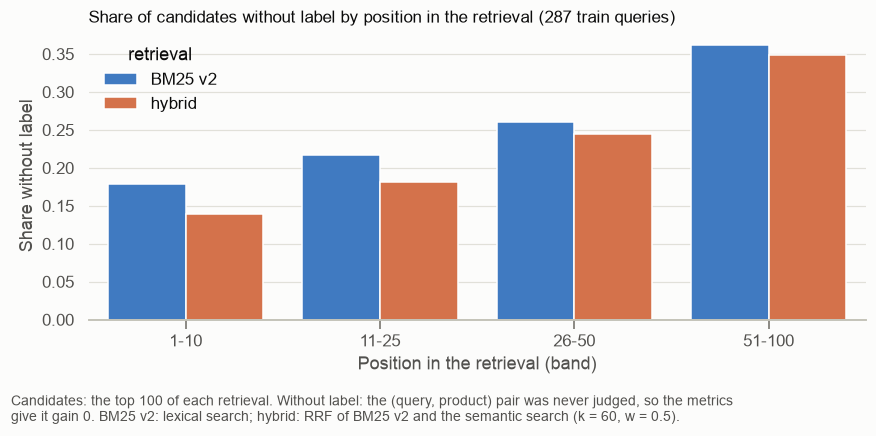

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
band_long = no_label_by_band.reset_index().melt("retrieval rank", var_name="retrieval", value_name="share")
sns.barplot(band_long, x="retrieval rank", y="share", hue="retrieval", palette=[plots.SERIES_1, plots.SERIES_2], ax=ax)
ax.set_title("Share of candidates without label by position in the retrieval (287 train queries)")
ax.set_xlabel("Position in the retrieval (band)")
ax.set_ylabel("Share without label")
fig.tight_layout()
plots.add_caption(fig, (
    "Candidates: the top 100 of each retrieval. Without label: the (query, product) pair was never judged, so the metrics "
    "give it gain 0. BM25 v2: lexical search; hybrid: RRF of BM25 v2 and the semantic search (k = 60, w = 0.5)."
))
plt.show()

**Resultados**
- **Cerca de 3 em cada 10 candidates não têm `label`:** 29,6% na BM25 v2 (8.409 de 28.438) e 27,6% na hybrid search (7.934 de 28.700). Só 4,7% e 4,2% são Irrelevant.
- **A fração sem `label` cresce com a posição:** de 17,9% (BM25 v2) e 13,9% (hybrid) nas posições 1 a 10 para 36,1% e 34,8% nas posições 51 a 100.
- **5 queries (BM25 v2) e 4 (hybrid) não têm nenhum candidate Exact ou Partial;** 6 queries têm menos de 100 candidates na BM25 v2.

**O que isso implica (nossa interpretação)**
- Os produtos julgados se concentram no topo dos retrievals, o que é compatível com um processo de julgamento que escolheu produtos parecidos com os que uma busca traria. Os produtos sem `label` são, em boa parte, os que ficam mais abaixo.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| 100 candidates por query, os mesmos que o reranker vê na busca | decidida | acrescentar os judged pairs que o retrieval não trouxe |
| Queries sem nenhum candidate Exact ou Partial ficam fora do treino, mas na avaliação | decidida | mantê-las no treino (não dão nenhum par para comparar) |

### 1.2 · O que cada forma de tratar os candidates sem `label` ensina ao modelo

O LambdaMART aprende com **pares** de produtos da mesma query que têm gains diferentes: um Exact contra um Partial, por exemplo. Dois produtos de gain 0 não formam par. Contamos os pares de treino nas duas variantes:
- **`drop`:** os candidates sem `label` saem dos exemplos de treino;
- **`zero`:** eles ficam, com gain 0.

As duas variantes ordenam todos os 100 candidates na avaliação. A diferença está só no que o modelo vê no treino.

In [4]:
PAIR_TYPES = [("Exact", "Partial"), ("Exact", "Irrelevant"), ("Partial", "Irrelevant"),
              ("Exact", ranking.NO_LABEL), ("Partial", ranking.NO_LABEL)]
pair_shares, pair_totals = {}, {}
for name, table in train_tables.items():
    for rule in ranking.UNLABELED_RULES:
        examples = ranking.training_examples(table, rule)
        per_query_counts = examples.groupby(["query_id", "label"]).size().unstack(fill_value=0)
        counts = pd.Series({f"{a} vs {b}": int((per_query_counts.get(a, 0) * per_query_counts.get(b, 0)).sum())
                            for a, b in PAIR_TYPES})
        pair_totals[(name, rule)] = int(counts.sum())
        pair_shares[f"{name}, {rule}"] = counts / counts.sum()
display(plots.table(pd.DataFrame(pair_shares).rename_axis("pair of labels"),
                    "Share of each kind of training pair, by retrieval and rule for candidates without label (287 train queries)",
                    note="A training pair: two candidates of the same query with different gains (Exact = 2, Partial = 1, "
                         "Irrelevant and, in the zero rule, no label = 0). Pairs of two gain-0 products do not count.",
                    precision=3))
print("training pairs: " + ", ".join(f"{name} {rule}: {total:,}" for (name, rule), total in pair_totals.items()))

,"BM25 v2, drop","BM25 v2, zero","hybrid, drop","hybrid, zero"
pair of labels,,,,
Exact vs Partial,0.699,0.246,0.722,0.264
Exact vs Irrelevant,0.107,0.038,0.095,0.035
Partial vs Irrelevant,0.194,0.068,0.183,0.067
Exact vs no label,0.000,0.187,0.000,0.182
Partial vs no label,0.000,0.461,0.000,0.453


training pairs: BM25 v2 drop: 184,145, BM25 v2 zero: 523,425, hybrid drop: 195,835, hybrid zero: 536,204


**Resultados**
- **Na `drop`, cerca de 70% dos pares são Exact × Partial** (69,9% na BM25 v2). Os pares com Irrelevant são o resto, porque só 4,7% dos candidates são Irrelevant.
- **Na `zero`, cerca de dois terços dos pares envolvem um produto sem `label`** (Partial × sem `label` e Exact × sem `label`: 46,1% e 18,7% na BM25 v2), e o número de pares quase triplica (de 184.145 para 523.425 na BM25 v2).

**O que isso implica (nossa interpretação)**
- Na `drop`, o modelo aprende sobretudo a separar Exact de Partial e quase nunca vê um produto fora do assunto como exemplo negativo.
- Na `zero`, ele aprende sobretudo a separar produtos julgados relevantes de produtos sem `label`. Se parte destes for relevante e só não tiver sido julgada (pooling bias), o modelo aprende a rebaixar produtos bons. A Etapa 3 mede qual variante ordena melhor.

## Etapa 2 · As features

O LambdaMART não lê texto: ele recebe uma tabela em que cada linha é um par (query, candidate) e cada coluna é uma feature. As 30 features estão em cinco grupos, definidos no `docs/EVALUATION.md` antes de qualquer número, para que as ablations da Etapa 5 meçam o que cada grupo agrega. Nenhuma feature usa `product_id`, `query_class` ou o `label`.

Toda feature é calculada para todo candidate, venha ele de qualquer retrieval: o score BM25 e a cosine similarity são calculados sobre o catalog inteiro. A exceção é o **BM25 v2 + reranker**, que usa só as 25 features que não dependem do embedding model (`features.LEXICAL_RERANKER_FEATURES`), para não precisar dele na busca.

### 2.1 · Os grupos de features

In [5]:
GROUP_DESCRIPTIONS = {
    "retrieval": "Score and position of the product in BM25 v2, in the semantic search and in the hybrid search (RRF), over the whole catalog.",
    "text": "BM25 score of each field alone; share of query tokens in each field; whole query in product_name; share of the query numbers in the product; cosine similarity with the short text.",
    "cross_encoder": "Score of the pre-trained cross-encoder for the query and the short text (product_name, product_class, category_hierarchy).",
    "numeric": "rating_count and review_count (log), average_rating, no rating, words of product_description, pairs of product_features, null product_class or category_hierarchy.",
    "query": "Number of query tokens and whether the query has a number. Equal for all candidates of a query.",
}
feature_groups_table = pd.DataFrame({
    "features": [len(group) for group in features.FEATURE_GROUPS.values()],
    "in the BM25 v2 reranker": [len([f for f in group if f in features.LEXICAL_RERANKER_FEATURES]) for group in features.FEATURE_GROUPS.values()],
    "what it measures": list(GROUP_DESCRIPTIONS.values()),
    "columns": [", ".join(group) for group in features.FEATURE_GROUPS.values()],
}, index=pd.Index(list(features.FEATURE_GROUPS), name="group"))
plots.table(feature_groups_table, "Feature groups of the reranker", precision=0, max_text_length=400,
            note="BM25 v2 reranker: without the 5 features that need the embedding model (semantic_cosine, semantic_rank, "
                 "rrf_score, rrf_rank, short_cosine). " + plots.TOKEN_DEFINITION)

,features,in the BM25 v2 reranker,what it measures,columns
group,,,,
retrieval,6,2,"Score and position of the product in BM25 v2, in the semantic search and in the hybrid search (RRF), over the whole catalog.","bm25_v2_score, bm25_v2_rank, semantic_cosine, semantic_rank, rrf_score, rrf_rank"
text,13,12,BM25 score of each field alone; share of query tokens in each field; whole query in product_name; share of the query numbers in the product; cosine similarity with the short text.,"bm25_product_name, bm25_product_class, bm25_category_hierarchy, bm25_product_description, bm25_product_features, coverage_product_name, coverage_product_class, coverage_category_hierarchy, coverage_product_description, coverage_product_features, query_in_product_name, number_match, short_cosine"
cross_encoder,1,1,"Score of the pre-trained cross-encoder for the query and the short text (product_name, product_class, category_hierarchy).",cross_encoder_score
numeric,8,8,"rating_count and review_count (log), average_rating, no rating, words of product_description, pairs of product_features, null product_class or category_hierarchy.","log_rating_count, log_review_count, average_rating, no_rating, description_words, feature_pairs, product_class_null, category_hierarchy_null"
query,2,2,Number of query tokens and whether the query has a number. Equal for all candidates of a query.,"query_tokens, query_has_number"


### 2.2 · Um exemplo: a query "bar stool 24 inches height"

Mostramos algumas features de seis candidates da hybrid search para uma query do train set: os três de maior `semantic_cosine` entre os que têm o número 24 no texto e os três de maior `semantic_cosine` entre os que não têm. `number_match` é a fração dos números da query (aqui, só o 24) presentes no texto do produto; é null quando a query não tem número.

In [6]:
EXAMPLE_QUERY = "bar stool 24 inches height"
example_query_id = int(queries.loc[queries["query"] == EXAMPLE_QUERY, "query_id"].iloc[0])
example_rows = train_tables["hybrid"][train_tables["hybrid"]["query_id"] == example_query_id]
example_rows = pd.concat([
    example_rows[example_rows["number_match"] == value].nlargest(3, "semantic_cosine") for value in (1.0, 0.0)
])
EXAMPLE_COLUMNS = ["label", "bm25_v2_score", "semantic_cosine", "coverage_product_name", "number_match", "cross_encoder_score", "log_rating_count"]
plots.table(example_rows.assign(product_name=example_rows["product_id"].map(product_names))
            .set_index("product_name")[EXAMPLE_COLUMNS],
            f"Some features of six hybrid search candidates for the train query '{EXAMPLE_QUERY}'", precision=2,
            note="coverage_product_name: share of the query tokens found in product_name. number_match: share of the query "
                 "numbers found in the product text (all fields). log_rating_count: log(1 + rating_count).")

,label,bm25_v2_score,semantic_cosine,coverage_product_name,number_match,cross_encoder_score,log_rating_count
product_name,,,,,,,
goberd 24 '' bar stools,Exact,7.90,0.82,0.60,1.00,2.82,6.88
york 24 '' bar stool,Exact,9.48,0.81,0.60,1.00,1.75,4.47
jerad wooden 24 '' bar stool,Exact,9.25,0.80,0.60,1.00,2.52,3.09
camargo swivel adjustable height bar stool,Partial,6.89,0.80,0.60,0.00,0.68,6.75
temelec swivel adjustable height bar stool,Partial,9.00,0.78,0.60,0.00,0.71,4.19
jazziah adjustable height stool,Partial,7.04,0.77,0.40,0.00,0.15,0.00


**Resultados**
- **Os três candidates com o 24 no texto são Exact, e os três sem o 24 são Partial,** embora a `semantic_cosine` seja parecida nos seis (de 0,77 a 0,82).

**O que isso implica (nossa interpretação)**
- Num caso assim, o número é o que separa Exact de Partial, e a semantic search quase não o enxerga. `number_match` dá esse sinal ao modelo numa coluna própria.

**Limitações**
- É uma única query, escolhida como exemplo. A distribuição das features no train set inteiro está na Etapa 2.3.

### 2.3 · As features separam os `label`?

Comparamos a mediana de cada feature entre Exact, Partial, Irrelevant e sem `label`, nos candidates do train set (união dos dois retrievals; cada par contado uma vez). É uma descrição: não diz quanto cada feature ajuda o modelo, o que a Etapa 5 mede.

In [7]:
train_union = pd.concat(train_tables.values()).drop_duplicates(["query_id", "product_id"])
LABEL_ORDER = ["Exact", "Partial", "Irrelevant", ranking.NO_LABEL]
median_by_label = train_union.groupby("label")[features.ALL_FEATURES].median().T[LABEL_ORDER]
median_by_label["null share"] = train_union[features.ALL_FEATURES].isna().mean()
plots.table(median_by_label.rename_axis("feature"),
            f"Median of each feature by label, {len(train_union):,} train candidates (union of both retrievals)", precision=3,
            note="null share: share of the candidates where the feature is null (number_match: queries without a number; "
                 "average_rating: products without rating). Ranks: 1 is the top of the catalog.")

label,Exact,Partial,Irrelevant,no label,null share
feature,,,,,
bm25_v2_score,5.348,5.274,3.741,3.849,0.000
bm25_v2_rank,46.000,61.000,68.000,76.000,0.000
semantic_cosine,0.754,0.717,0.660,0.671,0.000
semantic_rank,46.000,69.000,162.000,166.000,0.000
rrf_score,0.009,0.007,0.006,0.005,0.000
rrf_rank,42.000,59.000,75.000,84.000,0.000
bm25_product_name,3.575,3.489,2.765,1.341,0.000
bm25_product_class,1.664,1.910,0.000,1.005,0.000
bm25_category_hierarchy,1.985,2.472,1.304,1.474,0.000


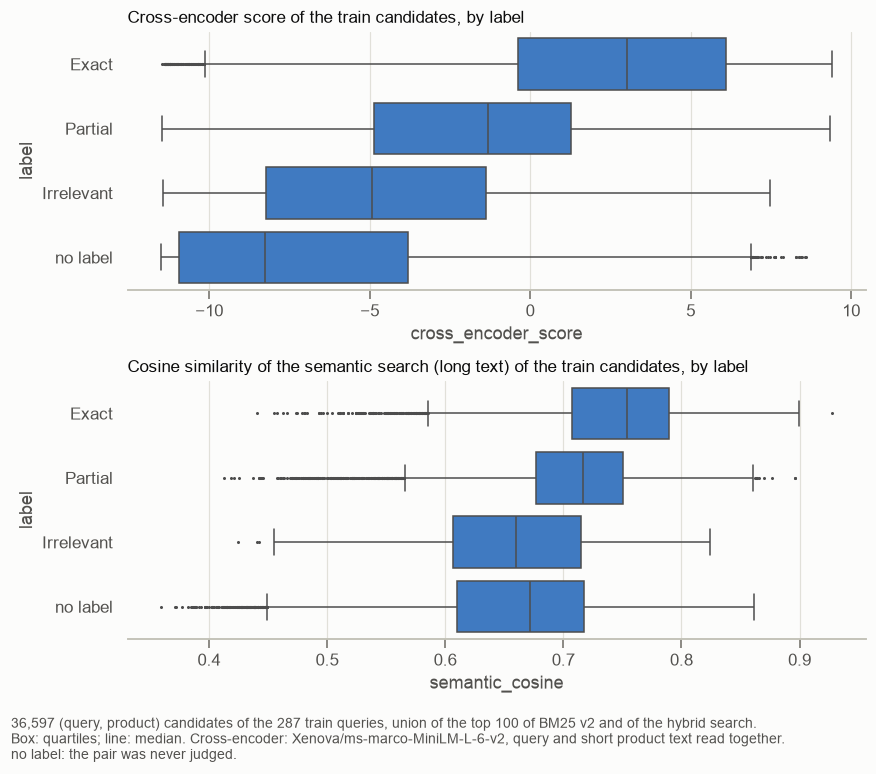

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6.5))
for ax, feature, title in zip(axes, ["cross_encoder_score", "semantic_cosine"],
                              ["Cross-encoder score", "Cosine similarity of the semantic search (long text)"]):
    sns.boxplot(train_union, x=feature, y="label", order=LABEL_ORDER, color=plots.SERIES_1, fliersize=1, ax=ax)
    ax.set_title(f"{title} of the train candidates, by label")
    ax.set_xlabel(feature)
    ax.set_ylabel("label")
fig.tight_layout()
plots.add_caption(fig, (
    f"{len(train_union):,} (query, product) candidates of the 287 train queries, union of the top 100 of BM25 v2 and of the "
    "hybrid search. Box: quartiles; line: median. Cross-encoder: Xenova/ms-marco-MiniLM-L-6-v2, query and short product text read "
    "together. no label: the pair was never judged."
))
plt.show()

**Resultados**
- **`cross_encoder_score` é a feature que mais separa os `label`:** mediana de 3,00 (Exact), −1,33 (Partial), −4,92 (Irrelevant) e −8,28 (sem `label`). É a única com diferença grande entre Exact e Partial.
- **Os candidates sem `label` ficam abaixo dos Irrelevant no `cross_encoder_score`,** e perto deles na `semantic_cosine` (0,671 contra 0,660) e no `bm25_v2_score` (3,85 contra 3,74).
- **Mais avaliações não indicam mais relevância:** a mediana de `log_rating_count` é 2,71 nos Exact e 3,22 nos Irrelevant.
- **`number_match` é null em 91,6% dos candidates,** os das queries sem número.

**O que isso implica (nossa interpretação)**
- A maior parte dos candidates sem `label` parece fora do assunto da query, o que favorece a variante `zero`. A Etapa 3.3 confere isso lendo os produtos de 10 queries.

**Limitações**
- Medianas não medem o efeito no modelo: features correlacionadas (por exemplo, os scores BM25 de cada field) podem ser redundantes.

## Etapa 3 · Tuning no train set (GroupKFold)

Os hiperparâmetros do LightGBM e a variante `drop` ou `zero` são escolhidos no train set, numa grade fixada no `docs/EVALUATION.md`. Como o reranker aprende com os `label`, usamos **GroupKFold**: as 287 queries do train set vão para 5 folds; cada modelo treina em 4 folds e ordena os 100 candidates das queries do quinto, inclusive os sem `label`. O NDCG@10 de cada query é calculado sobre essa ordem.

- **Grade:** `num_leaves` em {15, 31, 63}, `learning_rate` em {0,05; 0,1}, `min_data_in_leaf` em {20, 50}, 100, 300 ou 500 árvores, e as duas variantes: 72 combinações por retrieval. Fixos: `label_gain = [0, 1, 2]`, `lambdarank_truncation_level = 10`, `seed = 0`.
- **Regra:** fica a combinação de maior NDCG@10 médio; entre as que ficam a menos de 0,005 dela, a de menos árvores, depois a de menos folhas.

### 3.1 · As combinações escolhidas

Na primeira versão do tuning, o BM25 v2 + reranker usava as 30 features. Ela foi substituída antes de qualquer número de validação, quando decidimos que esse sistema não usa o embedding model (`docs/EVALUATION.md`). Aqui só roda a versão atual, com as 25 features.

In [9]:
folds = reranker.query_folds(train_queries["query_id"])
cv_per_query, cv_summary, chosen = {}, {}, {}
start = time.perf_counter()
for name, table in train_tables.items():
    cv_per_query[name] = reranker.cross_validate(table, train_runs[name], labels_by_query, SYSTEM_FEATURES[name], folds)
    cv_summary[name] = reranker.summarize_cv(cv_per_query[name])
    chosen[name] = reranker.select_combination(cv_summary[name])
print(f"GroupKFold of both retrievals in {time.perf_counter() - start:.0f} s")

for name in train_tables:
    display(plots.table(cv_summary[name].head(8).set_index(reranker.COMBINATION_COLUMNS),
                        f"Best 8 of the 72 tuning combinations for the {name} reranker, out of fold (287 train queries)",
                        precision=4, note="Mean over the 287 train queries, each scored by the model of the folds that do not "
                                          "contain it. MRR@10: 227 train queries with Exact."))
chosen_table = pd.DataFrame(chosen).T[reranker.COMBINATION_COLUMNS + ["ndcg@10", "condensed_ndcg@10"]]
plots.table(chosen_table.rename_axis("retrieval"), "Combination chosen for each reranker by the rule (fewest trees within 0.005)",
            precision=4)

GroupKFold of both retrievals in 568 s


,unlabeled,num_leaves,learning_rate,min_data_in_leaf,n_estimators,ndcg@10,condensed_ndcg@10
retrieval,,,,,,,
BM25 v2,zero,15,0.1000,50,100,0.7777,0.8372
hybrid,zero,15,0.1000,20,100,0.7944,0.8550


**Resultados**
- **Nos dois retrievals, fica a variante `zero` com 15 folhas, `learning_rate` 0,1 e 100 árvores;** `min_data_in_leaf` é 50 no BM25 v2 + reranker e 20 no hybrid search + reranker.
- **As escolhidas ficam a menos de 0,005 do máximo:** NDCG@10 fora do fold de 0,778 contra 0,780 (BM25 v2) e 0,794 contra 0,795 (hybrid).
- **As 8 melhores combinações de cada retrieval são todas `zero`.**

**Limitações**
- O NDCG@10 da combinação escolhida é otimista, porque é o melhor entre 72; serve só para escolher. A comparação entre sistemas é a do validation set (Etapa 4).

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| LambdaMART no LightGBM, grade de 72 combinações por retrieval, escolha por GroupKFold | decidida | XGBoost (`rank:ndcg`) ou CatBoost (`YetiRank`); busca aleatória numa grade maior; early stopping em cada fold |
| Variante `zero` (candidates sem `label` com gain 0) | decidida pela regra | `drop`, que vence no condensed NDCG@10 (Etapa 3.2) |

### 3.2 · `zero` contra `drop`: de onde vem a diferença

A regra escolhe pelo NDCG@10, que dá gain 0 aos produtos sem `label`. Uma variante que aprende a tirar esses produtos do topo ganha NDCG@10 sejam eles bons ou ruins. Para separar as duas coisas, comparamos as variantes, na combinação escolhida e fora do fold, também no **condensed NDCG@10**, que ignora os produtos sem `label`, e no **judged@10**.

In [10]:
oof_scores, oof_per_query = {}, {}
for name, table in train_tables.items():
    params, trees = reranker.combination_params(chosen[name]), int(chosen[name]["n_estimators"])
    oof_per_query[(name, "retrieval order")] = metrics.evaluate_run(train_runs[name], labels_by_query)
    for rule in ranking.UNLABELED_RULES:
        oof_scores[(name, rule)] = reranker.out_of_fold_scores(table, SYSTEM_FEATURES[name], folds, rule, params, trees)
        oof_per_query[(name, rule)] = reranker.evaluate_scores(train_runs[name], table, oof_scores[(name, rule)], labels_by_query)

display(plots.table(pd.DataFrame({f"{name} | {variant}": per_query[METRICS].mean() for (name, variant), per_query in oof_per_query.items()})
                    .T.rename_axis("retrieval | order"),
                    "Retrieval order and both rules of the chosen combination, out of fold (287 train queries)", precision=3,
                    note="drop: candidates without label left out of training; zero: kept with gain 0. Both order all 100 candidates. "
                         "MRR@10: 227 train queries with Exact."))

rule_comparisons = {}
for name in train_tables:
    for a, b in [("zero", "drop"), ("zero", "retrieval order"), ("drop", "retrieval order")]:
        rule_comparisons[(name, f"{a} − {b}")] = evaluate.compare_systems(
            oof_per_query[(name, a)][METRICS], oof_per_query[(name, b)][METRICS], METRICS, name_a=a, name_b=b)
plots.table(pd.DataFrame({f"{name} | {pair}": comparison["difference_ci"] for (name, pair), comparison in rule_comparisons.items()})
            .T.rename_axis("retrieval | difference"),
            "Paired differences between the rules and the retrieval order, out of fold (287 train queries)",
            note="Mean paired difference with 95% paired bootstrap interval (2,000 resamples, seed 0).")

,ndcg@10,condensed_ndcg@10,mrr@10,judged@10
retrieval | order,,,,
BM25 v2 | retrieval order,0.721,0.840,0.725,0.821
BM25 v2 | drop,0.724,0.847,0.718,0.812
BM25 v2 | zero,0.778,0.837,0.726,0.910
hybrid | retrieval order,0.763,0.862,0.736,0.861
hybrid | drop,0.749,0.861,0.737,0.839
hybrid | zero,0.794,0.855,0.746,0.908


,ndcg@10,condensed_ndcg@10,mrr@10,judged@10
retrieval | difference,,,,
BM25 v2 | zero − drop,0.053 [0.037; 0.070],-0.010 [-0.019; -0.002],0.008 [-0.020; 0.035],0.098 [0.078; 0.121]
BM25 v2 | zero − retrieval order,0.056 [0.039; 0.075],-0.002 [-0.012; 0.007],0.001 [-0.034; 0.038],0.089 [0.068; 0.110]
BM25 v2 | drop − retrieval order,0.003 [-0.011; 0.017],0.008 [-0.001; 0.017],-0.007 [-0.043; 0.029],-0.009 [-0.024; 0.005]
hybrid | zero − drop,0.045 [0.029; 0.061],-0.006 [-0.014; 0.002],0.009 [-0.018; 0.037],0.069 [0.049; 0.090]
hybrid | zero − retrieval order,0.032 [0.017; 0.046],-0.007 [-0.016; 0.002],0.009 [-0.023; 0.042],0.048 [0.033; 0.063]
hybrid | drop − retrieval order,-0.014 [-0.028; 0.001],-0.001 [-0.009; 0.006],0.000 [-0.032; 0.031],-0.022 [-0.038; -0.007]


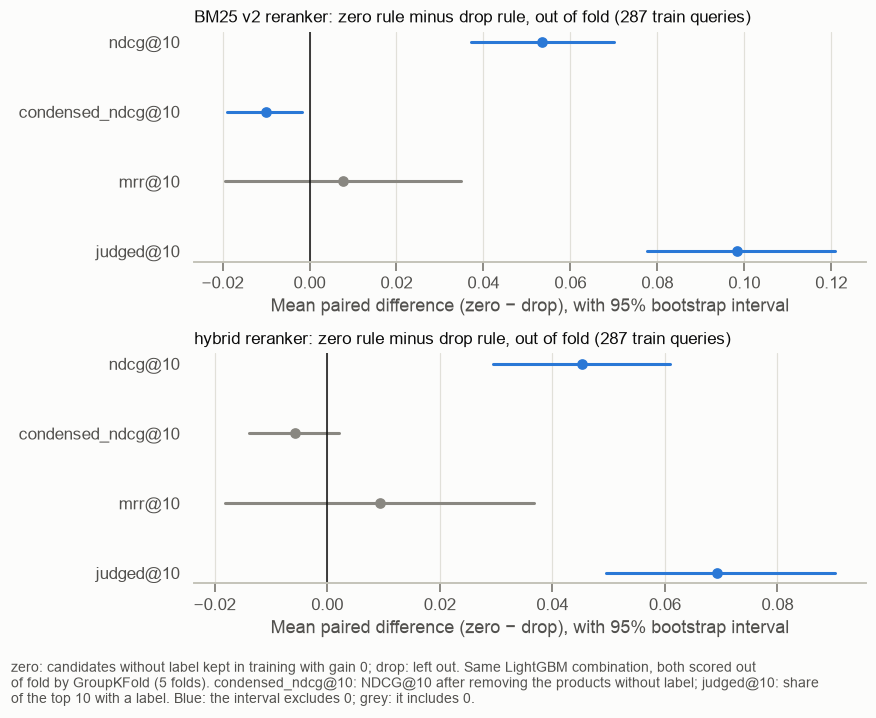

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6))
for ax, name in zip(axes, train_tables):
    comparison = rule_comparisons[(name, "zero − drop")]
    plots.difference_plot(ax, METRICS, comparison["difference"], comparison["difference_ci_low"], comparison["difference_ci_high"])
    ax.set_title(f"{name} reranker: zero rule minus drop rule, out of fold (287 train queries)")
    ax.set_xlabel("Mean paired difference (zero − drop), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "zero: candidates without label kept in training with gain 0; drop: left out. Same LightGBM combination, both scored out of "
    "fold by GroupKFold (5 folds). condensed_ndcg@10: NDCG@10 after removing the products without label; judged@10: share of the "
    "top 10 with a label. Blue: the interval excludes 0; grey: it includes 0."
))
plt.show()

**Resultados**
- **A `zero` vence a `drop` no NDCG@10 nos dois retrievals:** +0,053 [0,037; 0,070] (BM25 v2) e +0,045 [0,029; 0,061] (hybrid).
- **No condensed NDCG@10, a `drop` fica à frente ou a diferença não se distingue de 0:** −0,010 [−0,019; −0,002] (BM25 v2) e −0,006 [−0,014; 0,002] (hybrid).
- **O ganho da `zero` acompanha o judged@10:** +0,098 [0,078; 0,121] e +0,069 [0,049; 0,090] sobre a `drop`.
- **Contra a ordem do retrieval, a `zero` sobe o NDCG@10** (+0,056 [0,039; 0,075] na BM25 v2 e +0,032 [0,017; 0,046] na hybrid) **sem mudar o condensed NDCG@10** (−0,002 [−0,012; 0,007] e −0,007 [−0,016; 0,002]).
- **A `drop` não supera a ordem da hybrid search** (NDCG@10 −0,014 [−0,028; 0,001]).

**O que isso implica (nossa interpretação)**
- A `zero` ganha porque tira do topo produtos sem `label`, não porque ordena melhor os produtos julgados. Se esses produtos estão fora do assunto, o ganho é real; se são relevantes e só não foram julgados, é efeito do pooling bias. A Etapa 3.3 olha quais são.

**Limitações**
- Os intervalos não corrigem para várias comparações.
- O condensed NDCG@10 também tem limites: ele compara só os produtos julgados de cada query, que não são uma amostra aleatória dos candidates.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Seleção da variante pelo NDCG@10, com o condensed NDCG@10 reportado ao lado | decidida antes do tuning | escolher pelo condensed NDCG@10 (ficaria a `drop`); gain intermediário para candidates sem `label` |

### 3.3 · Quais produtos sem `label` a `zero` tira do topo

Na hybrid search, com a variante `zero` fora do fold, listamos os produtos que saem e que entram nos 10 primeiros em relação à ordem do retrieval, e o assistente de IA lê, sem revisão humana, 10 queries sorteadas (`seed = 0`) entre as que perdem algum produto sem `label` do top 10.

In [12]:
hybrid_oof_run = reranker.rerank_run(train_runs["hybrid"], train_tables["hybrid"], oof_scores[("hybrid", "zero")])
cross_encoder_scores = train_tables["hybrid"].set_index(["query_id", "product_id"])["cross_encoder_score"]
moved_rows = []
for query_id, reranked in hybrid_oof_run.items():
    before, after = train_runs["hybrid"][query_id][:10], reranked[:10]
    for direction, product_ids in (("leaves the top 10", set(before) - set(after)), ("enters the top 10", set(after) - set(before))):
        for product_id in product_ids:
            moved_rows.append({"query_id": query_id, "direction": direction, "product_id": product_id,
                               "label": labels_by_query.get(query_id, {}).get(product_id, ranking.NO_LABEL),
                               "cross_encoder_score": cross_encoder_scores.loc[(query_id, product_id)]})
moved_products = pd.DataFrame(moved_rows)
moved_summary = moved_products.groupby(["direction", "label"]).agg(
    products=("product_id", "size"), median_cross_encoder_score=("cross_encoder_score", "median"))
display(plots.table(moved_summary[["products"]].unstack("direction").droplevel(0, axis=1).reindex(LABEL_ORDER),
                    "Products that leave or enter the top 10 after reranking, hybrid search, zero rule, out of fold (287 train queries)",
                    precision=0))
plots.table(moved_summary[["median_cross_encoder_score"]].unstack("direction").droplevel(0, axis=1).reindex(LABEL_ORDER),
            "Median cross-encoder score of the products that leave or enter the top 10 (same data)", precision=2)

direction,enters the top 10,leaves the top 10
label,,
Exact,290,250
Partial,389,327
Irrelevant,54,19
no label,99,236


direction,enters the top 10,leaves the top 10
label,,
Exact,5.66,2.40
Partial,0.15,-1.27
Irrelevant,-2.48,-6.25
no label,-5.27,-5.96


In [13]:
INSPECTION_SEED = 0
inspection_rng = np.random.default_rng(INSPECTION_SEED)
queries_losing_unlabeled = moved_products.loc[(moved_products["direction"] == "leaves the top 10")
                                              & (moved_products["label"] == ranking.NO_LABEL), "query_id"].unique()
inspected_query_ids = sorted(inspection_rng.choice(queries_losing_unlabeled, size=10, replace=False))
inspection = moved_products[moved_products["query_id"].isin(inspected_query_ids)].assign(
    query=lambda frame: frame["query_id"].map(queries.set_index("query_id")["query"]),
    product_name=lambda frame: frame["product_id"].map(product_names),
).sort_values(["query_id", "direction", "label"], ascending=[True, False, True])
plots.table(inspection.set_index(["query", "direction"])[["label", "cross_encoder_score", "product_name"]],
            "Products that leave or enter the top 10 in 10 sampled train queries (hybrid search, zero rule, out of fold)",
            precision=2, max_text_length=90, note=f"Queries sampled with seed {INSPECTION_SEED} among those that lose at least "
                                                  "one product without label from the top 10.")

**Resultados**
- **Saem do top 10 236 produtos sem `label` e entram 99,** um saldo de −137 nas 287 queries, cerca de 0,5 por query. Entre os julgados, saem 250 Exact e entram 290; saem 327 Partial e entram 389.
- **Os produtos sem `label` que saem têm `cross_encoder_score` baixo:** mediana de −5,96, perto da dos Irrelevant que saem (−6,25) e bem abaixo da dos Partial que saem (−1,27).
- **Leitura das 10 queries sorteadas** (pelo assistente de IA, sem revisão humana e sem `label` novo): saem do top 10 23 produtos sem `label`.
  - **Cerca de 6 estão claramente fora do assunto:** uma torneira em "moen matte black hooks", dois azulejos de conchas em "living curtains pearl", uma cabeceira em "floating bed", um calço de cama em "high weight capacity bunk beds" e uma poltrona em "acrylic clear chair".
  - **Cerca de 13 parecem relevantes, quase sempre como um Partial:** três cortinas sheer em "living curtains pearl", três camas estofadas em "upholstered girls bed", cúpulas de vidro em "glass lsmp shades" e cinco azulejos em "lowes tile". Produtos parecidos da mesma query têm `label` Partial.
  - **4 são ambíguos,** como uma "twig tree" em "arched christmas tree".
- **O modelo também põe Irrelevant no topo:** em "floating bed", uma prateleira e uma mesa "floating"; em "auburn throw pillows", duas almofadas Irrelevant.
- **Em "lowes tile", o modelo troca azulejos sem `label` por outros azulejos sem `label`.**

**O que isso implica (nossa interpretação)**
- O ganho de NDCG@10 da `zero` é em parte real (tira do topo produtos fora do assunto) e em parte efeito do pooling bias (tira produtos provavelmente relevantes que não foram julgados). Nesta amostra, a segunda parte parece maior. Os `label` disponíveis não permitem medir as duas partes.

**Limitações**
- São 10 queries, lidas pelo assistente de IA, sem revisão humana e sem um `label` novo. É um indício qualitativo, não uma medida. Numa leitura anterior do assistente, fora do notebook e sem registro, com outras 10 queries, cerca de metade dos produtos sem `label` que saíam estava fora do assunto.

**Hipóteses para a error analysis (não conferidas)**
- Julgar uma amostra dos produtos sem `label` que o reranker tira do topo daria a fração de ganho real.

## Etapa 4 · O reranker no validation set

Os modelos finais são treinados em todo o train set com a combinação escolhida na Etapa 3.1 (variante `zero`) e rodam uma única vez nas 97 queries do validation set. Os candidates e as features do validation set são calculados aqui, da mesma forma que os do train set.

### 4.1 · Cada reranker contra a ordem do próprio retrieval

In [14]:
start = time.perf_counter()
validation_runs, validation_tables, validation_pairs = features.candidate_features(SYSTEMS, feature_builder, validation_queries,
                                                                                   labels_by_query)
print(f"features of the {validation_pairs:,} (query, product) pairs of the validation set in {time.perf_counter() - start:.0f} s")

training_examples = {name: ranking.training_examples(table, chosen[name]["unlabeled"]) for name, table in train_tables.items()}


def train_final(name, feature_columns, objective="lambdarank"):
    # Model of one retrieval, trained on the whole train set with the chosen combination.
    return reranker.fit(training_examples[name], feature_columns, reranker.combination_params(chosen[name]),
                        int(chosen[name]["n_estimators"]), objective=objective)


def validation_metrics(name, feature_columns, objective="lambdarank"):
    model = train_final(name, feature_columns, objective)
    scores = reranker.predict(model, validation_tables[name], feature_columns)
    return reranker.evaluate_scores(validation_runs[name], validation_tables[name], scores, labels_by_query), model


validation_per_query, final_models = {}, {}
for name in SYSTEMS:
    validation_per_query[(name, "retrieval order")] = metrics.evaluate_run(
        validation_runs[name], labels_by_query, metrics.SENSITIVITY_NDCG_CUTOFFS)
    validation_per_query[(name, "reranker")], final_models[name] = validation_metrics(name, SYSTEM_FEATURES[name])

SUMMARY_METRICS = METRICS + ["capped_recall@100", "capped_recall@100_exact_partial"]
validation_summary = pd.DataFrame({
    f"{name} | {variant}": evaluate.summary_table(validation_per_query[(name, variant)][SUMMARY_METRICS]).apply(
        lambda row: evaluate.format_ci(row["mean"], row["ci_low"], row["ci_high"]), axis=1)
    for name in SYSTEMS for variant in ("retrieval order", "reranker")
}).rename_axis("metric")
display(plots.table(validation_summary, "Retrieval order and reranker of each retrieval on the 97 validation queries",
                    note="Mean with 95% bootstrap interval. MRR@10 and Capped Recall@100: 77 validation queries with Exact. "
                         "capped_recall@100_exact_partial: Exact and Partial count as relevant (97 queries). "
                         "The reranker only reorders the top 100, so its Capped Recall@100 equals the retrieval's."))

reranker_gain = {name: evaluate.compare_systems(validation_per_query[(name, "reranker")][METRICS],
                                                validation_per_query[(name, "retrieval order")][METRICS], METRICS,
                                                name_a="reranker", name_b="retrieval order") for name in SYSTEMS}
plots.table(pd.DataFrame({name: comparison["difference_ci"] for name, comparison in reranker_gain.items()}).rename_axis("metric"),
            "Reranker minus the order of its own retrieval, 97 validation queries",
            note="Mean paired difference with 95% paired bootstrap interval. MRR@10: 77 queries with Exact.")

features of the 12,433 (query, product) pairs of the validation set in 39 s


,BM25 v2 | retrieval order,BM25 v2 | reranker,hybrid | retrieval order,hybrid | reranker
metric,,,,
ndcg@10,0.653 [0.589; 0.718],0.744 [0.682; 0.802],0.747 [0.690; 0.805],0.772 [0.720; 0.827]
condensed_ndcg@10,0.799 [0.749; 0.851],0.802 [0.749; 0.852],0.834 [0.787; 0.879],0.832 [0.788; 0.875]
mrr@10,0.661 [0.564; 0.752],0.710 [0.615; 0.797],0.681 [0.585; 0.766],0.699 [0.603; 0.786]
judged@10,0.782 [0.719; 0.839],0.890 [0.836; 0.935],0.854 [0.805; 0.900],0.890 [0.843; 0.934]
capped_recall@100,0.705 [0.628; 0.778],0.705 [0.628; 0.778],0.714 [0.640; 0.784],0.714 [0.640; 0.784]
capped_recall@100_exact_partial,0.661 [0.600; 0.721],0.661 [0.597; 0.721],0.694 [0.639; 0.747],0.694 [0.639; 0.747]


,BM25 v2,hybrid
metric,,
ndcg@10,0.091 [0.059; 0.126],0.025 [0.009; 0.043]
condensed_ndcg@10,0.003 [-0.018; 0.025],-0.002 [-0.013; 0.010]
mrr@10,0.049 [-0.004; 0.109],0.018 [-0.016; 0.052]
judged@10,0.107 [0.073; 0.145],0.036 [0.019; 0.056]


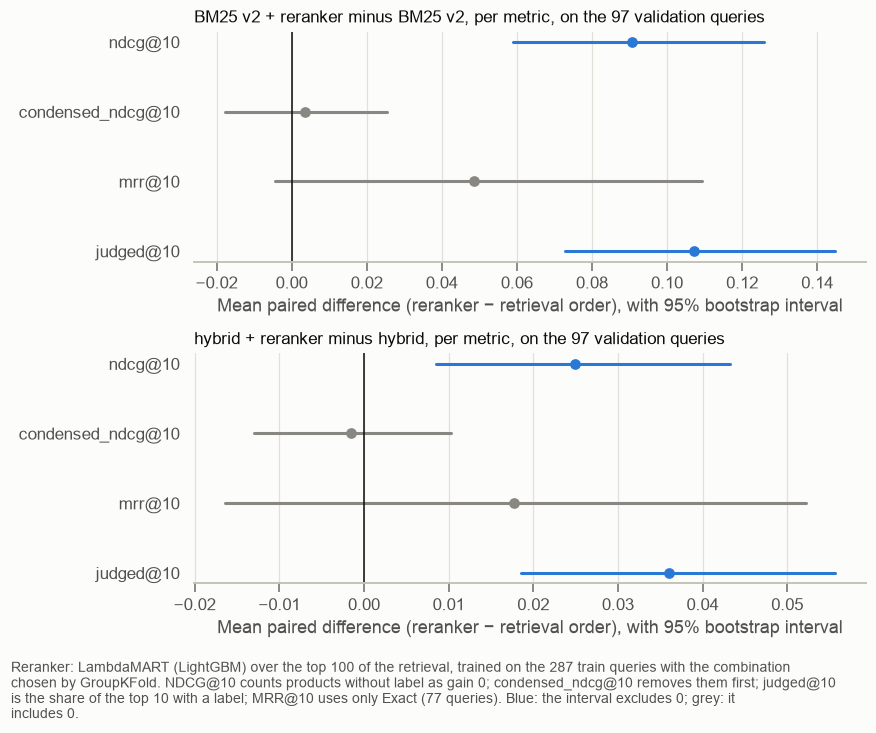

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(8, 6))
for ax, name in zip(axes, SYSTEMS):
    comparison = reranker_gain[name]
    plots.difference_plot(ax, METRICS, comparison["difference"], comparison["difference_ci_low"], comparison["difference_ci_high"])
    ax.set_title(f"{name} + reranker minus {name}, per metric, on the 97 validation queries")
    ax.set_xlabel("Mean paired difference (reranker − retrieval order), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Reranker: LambdaMART (LightGBM) over the top 100 of the retrieval, trained on the 287 train queries with the combination "
    "chosen by GroupKFold. NDCG@10 counts products without label as gain 0; condensed_ndcg@10 removes them first; judged@10 is the "
    "share of the top 10 with a label; MRR@10 uses only Exact (77 queries). Blue: the interval excludes 0; grey: it includes 0."
))
plt.show()

**Resultados**
- **O reranker sobe o NDCG@10 dos dois retrievals:** BM25 v2 de 0,653 para 0,744 (+0,091 [0,059; 0,126]) e hybrid search de 0,747 para 0,772 (+0,025 [0,009; 0,043]).
- **O condensed NDCG@10 não muda:** +0,003 [−0,018; 0,025] (BM25 v2) e −0,002 [−0,013; 0,010] (hybrid).
- **O judged@10 sobe:** +0,107 [0,073; 0,145] e +0,036 [0,019; 0,056].
- **O MRR@10 não se distingue de 0:** +0,049 [−0,004; 0,109] e +0,018 [−0,016; 0,052].

**O que isso implica (nossa interpretação)**
- O padrão do train set (Etapa 3.2) se repete: o ganho vem de trazer ao topo produtos com `label`, e não de ordenar melhor os produtos julgados. Pela Etapa 3.3, parte desse ganho é real e parte é efeito do pooling bias.

**Limitações**
- 97 queries; um ganho pequeno na ordem dos produtos julgados (abaixo de uns 0,02) não seria detectado.

### 4.2 · O ganho depende do corte em 10?

Repetimos a comparação da Etapa 4.1 com o NDCG cortado em 5 e em 15, como análise de sensibilidade registrada no `docs/EVALUATION.md`. Nenhuma escolha usa esses números.

In [16]:
CUTOFF_METRICS = ["ndcg@5", "ndcg@10", "ndcg@15"]
cutoff_comparisons = {name: evaluate.compare_systems(validation_per_query[(name, "reranker")][CUTOFF_METRICS],
                                                     validation_per_query[(name, "retrieval order")][CUTOFF_METRICS],
                                                     CUTOFF_METRICS, name_a="reranker", name_b="retrieval order")
                      for name in SYSTEMS}
plots.table(pd.DataFrame({name: comparison["difference_ci"] for name, comparison in cutoff_comparisons.items()}).rename_axis("metric"),
            "Reranker minus retrieval order at three NDCG cutoffs, 97 validation queries",
            note="Same gains as NDCG@10 (Exact = 2, Partial = 1, Irrelevant and no label = 0). Mean paired difference with 95% "
                 "paired bootstrap interval.")

,BM25 v2,hybrid
metric,,
ndcg@5,0.098 [0.054; 0.147],0.026 [0.004; 0.051]
ndcg@10,0.091 [0.059; 0.126],0.025 [0.009; 0.043]
ndcg@15,0.085 [0.059; 0.115],0.023 [0.010; 0.038]


**Resultados**
- **O ganho aparece nos três cortes, com intervalos que excluem 0:** na BM25 v2, +0,098 [0,054; 0,147] (@5), +0,091 (@10) e +0,085 [0,059; 0,115] (@15); na hybrid, +0,026 [0,004; 0,051], +0,025 e +0,023 [0,010; 0,038].

**O que isso implica (nossa interpretação)**
- A conclusão da Etapa 4.1 não depende do corte em 10.

### 4.3 · Hybrid search + reranker contra BM25 v2 + reranker

Os dois sistemas diferem só no embedding model: o hybrid search + reranker o usa no retrieval e em 5 features; o BM25 v2 + reranker não o usa. O cross-encoder está nos dois. Comparamos também:
- os dois sem o cross-encoder (mesma combinação, sem o grupo cross_encoder);
- o BM25 v2 + reranker com as 5 features de embedding acrescentadas, que isola o efeito só dos candidates.

In [17]:
no_cross_encoder = {name: [f for f in SYSTEM_FEATURES[name] if f not in features.FEATURE_GROUPS["cross_encoder"]] for name in SYSTEMS}
for name in SYSTEMS:
    validation_per_query[(name, "without cross_encoder")], _ = validation_metrics(name, no_cross_encoder[name])
validation_per_query[("BM25 v2", "with embedding features")], _ = validation_metrics("BM25 v2", features.ALL_FEATURES)

SYSTEM_COMPARISONS = {
    "hybrid + reranker − BM25 v2 + reranker": (("hybrid", "reranker"), ("BM25 v2", "reranker")),
    "both without cross_encoder: hybrid − BM25 v2": (("hybrid", "without cross_encoder"), ("BM25 v2", "without cross_encoder")),
    "BM25 v2 + reranker: with − without embedding features": (("BM25 v2", "with embedding features"), ("BM25 v2", "reranker")),
}
COMPARISON_METRICS = ["ndcg@10", "condensed_ndcg@10", "mrr@10", "judged@10", "ndcg@5"]
system_comparisons = {label: evaluate.compare_systems(validation_per_query[a][COMPARISON_METRICS], validation_per_query[b][COMPARISON_METRICS],
                                                      COMPARISON_METRICS, name_a="a", name_b="b")
                      for label, (a, b) in SYSTEM_COMPARISONS.items()}
print("mean NDCG@10: " + ", ".join(f"{name} | {variant} {per_query['ndcg@10'].mean():.3f}"
                                    for (name, variant), per_query in validation_per_query.items()
                                    if variant in ("without cross_encoder", "with embedding features")))
plots.table(pd.DataFrame({label: comparison["difference_ci"] for label, comparison in system_comparisons.items()}).T.rename_axis("comparison"),
            "Comparisons between the two rerankers, 97 validation queries",
            note="Mean paired difference with 95% paired bootstrap interval. Embedding features: semantic_cosine, semantic_rank, "
                 "rrf_score, rrf_rank, short_cosine. MRR@10: 77 queries with Exact.")

mean NDCG@10: BM25 v2 | without cross_encoder 0.740, hybrid | without cross_encoder 0.776, BM25 v2 | with embedding features 0.767


,ndcg@10,condensed_ndcg@10,mrr@10,judged@10,ndcg@5
comparison,,,,,
hybrid + reranker − BM25 v2 + reranker,0.028 [0.010; 0.048],0.030 [0.011; 0.050],-0.011 [-0.061; 0.036],0.009 [-0.009; 0.028],0.028 [0.005; 0.053]
both without cross_encoder: hybrid − BM25 v2,0.036 [0.013; 0.059],0.025 [0.007; 0.045],-0.011 [-0.062; 0.037],0.021 [0.002; 0.043],0.039 [0.010; 0.068]
BM25 v2 + reranker: with − without embedding features,0.024 [0.006; 0.042],0.016 [0.004; 0.028],0.012 [-0.049; 0.076],0.010 [-0.008; 0.030],0.028 [0.006; 0.051]


**Resultados**
- **O hybrid search + reranker supera o BM25 v2 + reranker no NDCG@10 e no condensed NDCG@10:** +0,028 [0,010; 0,048] e +0,030 [0,011; 0,050]; o judged@10 não se distingue (+0,009 [−0,009; 0,028]).
- **Sem o cross-encoder nos dois, a diferença se mantém:** NDCG@10 +0,036 [0,013; 0,059].
- **As features de embedding sobem o BM25 v2 + reranker de 0,744 para 0,767** (+0,024 [0,006; 0,042]; condensed +0,016 [0,004; 0,028]), ainda abaixo dos 0,772 do hybrid search + reranker.

**O que isso implica (nossa interpretação)**
- Diferente do ganho do reranker sobre o retrieval (Etapa 4.1), a vantagem do embedding model aparece também na ordem dos produtos julgados. A maior parte dela vem das features de embedding; o conjunto de candidates da hybrid search agrega pouco além disso.

**Limitações**
- A diferença entre o BM25 v2 + reranker com features de embedding (0,767) e o hybrid search + reranker (0,772) não foi testada com o paired bootstrap.

## Etapa 5 · O que cada parte do reranker agrega

Todas as variantes usam a combinação escolhida na Etapa 3.1, sem novo tuning, e rodam uma vez no validation set. As comparações são lidas como descrição do que cada parte agrega, não como uma série de testes de aprovação.

### 5.1 · O cross-encoder

Três comparações registradas no `docs/EVALUATION.md`: o reranker com e sem o grupo cross_encoder, em cada retrieval; o cross-encoder sozinho ordenando os mesmos 100 candidates; e os dois sistemas sem o cross-encoder (Etapa 4.3).

In [18]:
for name in SYSTEMS:
    validation_per_query[(name, "cross-encoder alone")] = reranker.evaluate_scores(
        validation_runs[name], validation_tables[name], validation_tables[name]["cross_encoder_score"].to_numpy(), labels_by_query)

CROSS_ENCODER_VARIANTS = ["retrieval order", "reranker", "without cross_encoder", "cross-encoder alone"]
display(plots.table(pd.DataFrame({f"{name} | {variant}": validation_per_query[(name, variant)][METRICS].mean()
                                  for name in SYSTEMS for variant in CROSS_ENCODER_VARIANTS}).T.rename_axis("retrieval | order"),
                    "Rerankers with and without the cross-encoder, and the cross-encoder alone, 97 validation queries", precision=3,
                    note="cross-encoder alone: the top 100 of the retrieval ordered by cross_encoder_score. MRR@10: 77 queries with Exact."))
cross_encoder_comparisons = {}
for name in SYSTEMS:
    for other in ("without cross_encoder", "cross-encoder alone"):
        cross_encoder_comparisons[f"{name}: reranker − {other}"] = evaluate.compare_systems(
            validation_per_query[(name, "reranker")][METRICS], validation_per_query[(name, other)][METRICS], METRICS, name_a="a", name_b="b")
cross_encoder_comparisons["hybrid: cross-encoder alone − retrieval order"] = evaluate.compare_systems(
    validation_per_query[("hybrid", "cross-encoder alone")][METRICS], validation_per_query[("hybrid", "retrieval order")][METRICS],
    METRICS, name_a="a", name_b="b")
plots.table(pd.DataFrame({label: comparison["difference_ci"] for label, comparison in cross_encoder_comparisons.items()}).T
            .rename_axis("comparison"), "What the cross-encoder adds, 97 validation queries",
            note="Mean paired difference with 95% paired bootstrap interval.")

,ndcg@10,condensed_ndcg@10,mrr@10,judged@10
retrieval | order,,,,
BM25 v2 | retrieval order,0.653,0.799,0.661,0.782
BM25 v2 | reranker,0.744,0.802,0.710,0.890
BM25 v2 | without cross_encoder,0.740,0.806,0.719,0.888
BM25 v2 | cross-encoder alone,0.718,0.784,0.700,0.876
hybrid | retrieval order,0.747,0.834,0.681,0.854
hybrid | reranker,0.772,0.832,0.699,0.890
hybrid | without cross_encoder,0.776,0.831,0.708,0.899
hybrid | cross-encoder alone,0.720,0.793,0.683,0.865


,ndcg@10,condensed_ndcg@10,mrr@10,judged@10
comparison,,,,
BM25 v2: reranker − without cross_encoder,0.003 [-0.016; 0.024],-0.003 [-0.018; 0.012],-0.010 [-0.046; 0.029],0.002 [-0.011; 0.019]
BM25 v2: reranker − cross-encoder alone,0.026 [-0.004; 0.055],0.019 [-0.002; 0.037],0.010 [-0.051; 0.075],0.014 [-0.018; 0.045]
hybrid: reranker − without cross_encoder,-0.005 [-0.015; 0.006],0.001 [-0.007; 0.009],-0.009 [-0.039; 0.021],-0.009 [-0.021; 0.002]
hybrid: reranker − cross-encoder alone,0.051 [0.018; 0.086],0.039 [0.016; 0.064],0.016 [-0.045; 0.081],0.025 [-0.002; 0.054]
hybrid: cross-encoder alone − retrieval order,-0.027 [-0.064; 0.012],-0.041 [-0.070; -0.012],0.002 [-0.059; 0.063],0.011 [-0.018; 0.037]


**Resultados**
- **Tirar o cross-encoder não muda o NDCG@10 de nenhum dos dois rerankers:** reranker − sem cross-encoder = +0,003 [−0,016; 0,024] (BM25 v2) e −0,005 [−0,015; 0,006] (hybrid). Sem ele, o hybrid search + reranker fica em 0,776.
- **O cross-encoder sozinho ordena pior que o reranker:** reranker − cross-encoder sozinho = +0,026 [−0,004; 0,055] (BM25 v2) e +0,051 [0,018; 0,086] (hybrid).
- **Na hybrid search, o cross-encoder sozinho não supera a ordem do próprio retrieval:** −0,027 [−0,064; 0,012].

**O que isso implica (nossa interpretação)**
- A informação que o cross-encoder traz já está nas outras features (scores de texto por field e, no hybrid, os embeddings). Na Etapa 2.3 ele era a feature que mais separava os `label` sozinha, mas não agrega ao modelo.

**Limitações**
- Um único cross-encoder, pequeno (MiniLM com 6 camadas, treinado no MS MARCO), sem fine-tuning. Um modelo maior ou ajustado ao WANDS pode agregar.

### 5.2 · O objetivo por pares (LambdaMART contra pointwise)

O baseline pointwise é o mesmo LightGBM, com as mesmas features, os mesmos exemplos (`zero`) e os mesmos hiperparâmetros, treinado para prever o gain de cada produto isoladamente (`objective = regression`).

In [19]:
for name in SYSTEMS:
    validation_per_query[(name, "pointwise")], _ = validation_metrics(name, SYSTEM_FEATURES[name], objective="regression")
pointwise_comparisons = {name: evaluate.compare_systems(validation_per_query[(name, "reranker")][METRICS],
                                                        validation_per_query[(name, "pointwise")][METRICS], METRICS,
                                                        name_a="lambdarank", name_b="pointwise") for name in SYSTEMS}
print("mean NDCG@10 of the pointwise baseline: " + ", ".join(
    f"{name} {validation_per_query[(name, 'pointwise')]['ndcg@10'].mean():.3f}" for name in SYSTEMS))
plots.table(pd.DataFrame({name: comparison["difference_ci"] for name, comparison in pointwise_comparisons.items()}).rename_axis("metric"),
            "LambdaMART minus the pointwise baseline, 97 validation queries",
            note="Same features, training examples and hyperparameters; only the LightGBM objective changes. "
                 "Mean paired difference with 95% paired bootstrap interval.")

mean NDCG@10 of the pointwise baseline: BM25 v2 0.729, hybrid 0.740


,BM25 v2,hybrid
metric,,
ndcg@10,0.014 [-0.005; 0.033],0.032 [0.009; 0.056]
condensed_ndcg@10,0.014 [0.000; 0.028],0.036 [0.016; 0.058]
mrr@10,0.043 [-0.015; 0.106],0.024 [-0.032; 0.079]
judged@10,-0.002 [-0.023; 0.017],-0.003 [-0.020; 0.014]


**Resultados**
- **Na hybrid search, o LambdaMART supera o pointwise:** NDCG@10 +0,032 [0,009; 0,056] e condensed NDCG@10 +0,036 [0,016; 0,058].
- **Na BM25 v2, a diferença não se distingue de 0 no NDCG@10:** +0,014 [−0,005; 0,033]; no condensed NDCG@10, +0,014 [0,000; 0,028].

**O que isso implica (nossa interpretação)**
- Comparar produtos da mesma query no treino ajuda a ordenar, sobretudo quando os candidates já são bons (hybrid search).

### 5.3 · Ablations por grupo de features

Cada linha é o reranker treinado sem um grupo de features (ou sem as colunas de rating: `log_rating_count`, `log_review_count`, `average_rating` e `no_rating`). A diferença é **reranker completo − sem o grupo**: positiva quando o grupo ajuda. No hybrid search + reranker, a ablation das 5 features de embedding também entra.

In [20]:
ablation_sets = {name: features.ablation_feature_sets(SYSTEM_FEATURES[name]) for name in SYSTEMS}
ablation_sets["hybrid"]["without embedding features"] = features.LEXICAL_RERANKER_FEATURES
ablation_comparisons = {}
for name, sets in ablation_sets.items():
    for variant, feature_columns in sets.items():
        if (name, variant) not in validation_per_query:
            validation_per_query[(name, variant)], _ = validation_metrics(name, feature_columns)
        ablation_comparisons[(name, variant)] = evaluate.compare_systems(
            validation_per_query[(name, "reranker")][["ndcg@10", "condensed_ndcg@10"]],
            validation_per_query[(name, variant)][["ndcg@10", "condensed_ndcg@10"]], ["ndcg@10", "condensed_ndcg@10"],
            name_a="full", name_b="ablation")
plots.table(pd.DataFrame({
    "NDCG@10 without the group": {key: validation_per_query[key]["ndcg@10"].mean() for key in ablation_comparisons},
}).join(pd.DataFrame({
    "full − without (NDCG@10)": {key: comparison.loc["ndcg@10", "difference_ci"] for key, comparison in ablation_comparisons.items()},
    "full − without (condensed)": {key: comparison.loc["condensed_ndcg@10", "difference_ci"] for key, comparison in ablation_comparisons.items()},
})).rename_axis(["retrieval", "ablation"]), "Ablations of the rerankers, 97 validation queries", precision=3,
    note="Each ablation trains the chosen combination without the listed features. Mean paired difference (full reranker − "
         "ablation) with 95% paired bootstrap interval: positive when the group helps.")

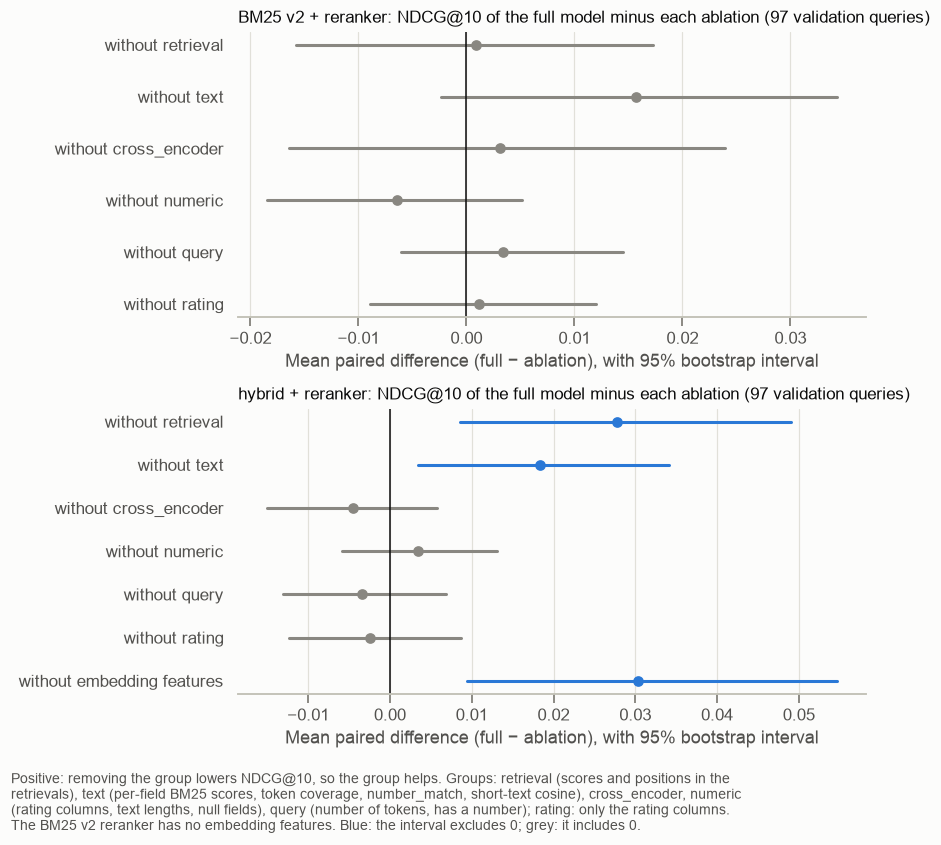

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(8, 7))
for ax, name in zip(axes, SYSTEMS):
    variants = list(ablation_sets[name])
    rows = [ablation_comparisons[(name, variant)].loc["ndcg@10"] for variant in variants]
    plots.difference_plot(ax, variants, [row["difference"] for row in rows], [row["difference_ci_low"] for row in rows],
                          [row["difference_ci_high"] for row in rows])
    ax.set_title(f"{name} + reranker: NDCG@10 of the full model minus each ablation (97 validation queries)")
    ax.set_xlabel("Mean paired difference (full − ablation), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Positive: removing the group lowers NDCG@10, so the group helps. Groups: retrieval (scores and positions in the retrievals), "
    "text (per-field BM25 scores, token coverage, number_match, short-text cosine), cross_encoder, numeric (rating columns, text "
    "lengths, null fields), query (number of tokens, has a number); rating: only the rating columns. The BM25 v2 reranker has no "
    "embedding features. Blue: the interval excludes 0; grey: it includes 0."
))
plt.show()

**Resultados**
- **No hybrid search + reranker, três grupos ajudam, com intervalos que excluem 0:** retrieval +0,028 [0,009; 0,049], features de embedding +0,030 [0,009; 0,055] e text +0,018 [0,003; 0,034].
- **No BM25 v2 + reranker, nenhum grupo sozinho tem efeito distinguível de 0;** o maior é text, +0,016 [−0,002; 0,034].
- **Os grupos numeric e query e as colunas de rating não mostram efeito no NDCG@10 em nenhum dos dois sistemas:** as diferenças vão de −0,006 a +0,003, todas com intervalos que incluem 0.
- **A exceção é o condensed NDCG@10 do hybrid search + reranker sem o grupo numeric:** +0,010 [0,004; 0,017]. As colunas de rating sozinhas não têm esse efeito (+0,005 [−0,001; 0,011]).

**O que isso implica (nossa interpretação)**
- As features numéricas do produto, incluindo `rating_count`, `average_rating` e `review_count`, quase não ajudam a prever o `label` nestes candidates. O pequeno efeito do grupo numeric na ordem dos produtos julgados do hybrid vem das outras features do grupo (tamanho dos textos, fields null), não das colunas de rating. Isso não diz que popularidade é inútil em produção: o `label` mede se o produto atende à query, não se ele vende.
- No BM25 v2 + reranker, os grupos parecem redundantes entre si: tirar qualquer um deles sozinho não muda o resultado, porque os outros carregam informação parecida.

**Limitações**
- Cada ablation tira um grupo de cada vez; grupos redundantes podem parecer inúteis um a um.
- Sem novo tuning: um modelo sem um grupo poderia ter outra combinação melhor.
- Muitas comparações sem correção para comparações múltiplas.

#### 5.3.1 · Ablations do sistema escolhido (hybrid search + reranker sem o cross-encoder)

As ablations da Etapa 5.3 foram feitas sobre o hybrid search + reranker **com** o cross-encoder (30 features, NDCG@10 de 0,772 no validation set). O sistema escolhido na Etapa 7 é a versão **sem** o cross-encoder (29 features, NDCG@10 de 0,776). Como o cross-encoder lê o texto da query e do produto, ele pode ter compensado parte da perda quando outro grupo saiu. Por isso, repetimos aqui as ablations sobre o modelo escolhido.

- **Quando:** seção acrescentada em 2026-11-09, **depois** da execução única do test set. Ela usa só o validation set, é lida como descrição e não muda a seleção nem os números do test set.
- **Como:** o mesmo procedimento da Etapa 5.3. Cada linha é o modelo escolhido treinado de novo sem um grupo de features, com a mesma combinação de hiperparâmetros e sem novo tuning. A diferença é **escolhido − sem o grupo**: positiva quando o grupo ajuda.
- **Grupos:** retrieval, text, numeric e query (`features.FEATURE_GROUPS`), as colunas de rating e as 5 features de embedding. O grupo cross_encoder não entra, porque o modelo escolhido não o usa.


In [22]:
selected_features = no_cross_encoder["hybrid"]
selected_ablation_sets = features.ablation_feature_sets(selected_features)
selected_ablation_sets["without embedding features"] = [f for f in selected_features if f not in features.EMBEDDING_FEATURES]
ABLATION_METRICS = ["ndcg@10", "condensed_ndcg@10"]
selected_per_query = validation_per_query[("hybrid", "without cross_encoder")]
selected_ablation_per_query, selected_ablation_comparisons = {}, {}
for variant, feature_columns in selected_ablation_sets.items():
    selected_ablation_per_query[variant], _ = validation_metrics("hybrid", feature_columns)
    selected_ablation_comparisons[variant] = evaluate.compare_systems(
        selected_per_query[ABLATION_METRICS], selected_ablation_per_query[variant][ABLATION_METRICS], ABLATION_METRICS,
        name_a="selected", name_b="ablation")
print(f"selected system: {len(selected_features)} features, mean NDCG@10 {selected_per_query['ndcg@10'].mean():.3f}")
display(plots.table(pd.DataFrame({
    "features": {variant: len(columns) for variant, columns in selected_ablation_sets.items()},
}).rename_axis("ablation"), "Number of features of each ablation of the selected system"))
plots.table(pd.DataFrame({
    "NDCG@10 without the group": {variant: per_query["ndcg@10"].mean() for variant, per_query in selected_ablation_per_query.items()},
    "selected − without (NDCG@10)": {variant: comparison.loc["ndcg@10", "difference_ci"]
                                     for variant, comparison in selected_ablation_comparisons.items()},
    "selected − without (condensed)": {variant: comparison.loc["condensed_ndcg@10", "difference_ci"]
                                       for variant, comparison in selected_ablation_comparisons.items()},
}).rename_axis("ablation"), "Ablations of the selected system (hybrid search + reranker without the cross-encoder), 97 validation queries",
    precision=3,
    note="Each ablation trains the selected system's combination without the listed features, with no new tuning. Mean paired "
         "difference (selected − ablation) with 95% paired bootstrap interval: positive when the group helps. Embedding features: "
         "semantic_cosine, semantic_rank, rrf_score, rrf_rank, short_cosine.")


selected system: 29 features, mean NDCG@10 0.776


,features
ablation,
without retrieval,23
without text,16
without numeric,21
without query,27
without rating,25
without embedding features,24


,NDCG@10 without the group,selected − without (NDCG@10),selected − without (condensed)
ablation,,,
without retrieval,0.746,0.030 [0.005; 0.057],0.031 [0.009; 0.053]
without text,0.733,0.043 [0.025; 0.064],0.002 [-0.010; 0.016]
without numeric,0.774,0.002 [-0.009; 0.013],0.003 [-0.005; 0.011]
without query,0.770,0.006 [-0.002; 0.015],0.006 [-0.000; 0.014]
without rating,0.772,0.004 [-0.006; 0.015],0.004 [-0.003; 0.014]
without embedding features,0.740,0.036 [0.013; 0.060],0.022 [0.006; 0.039]


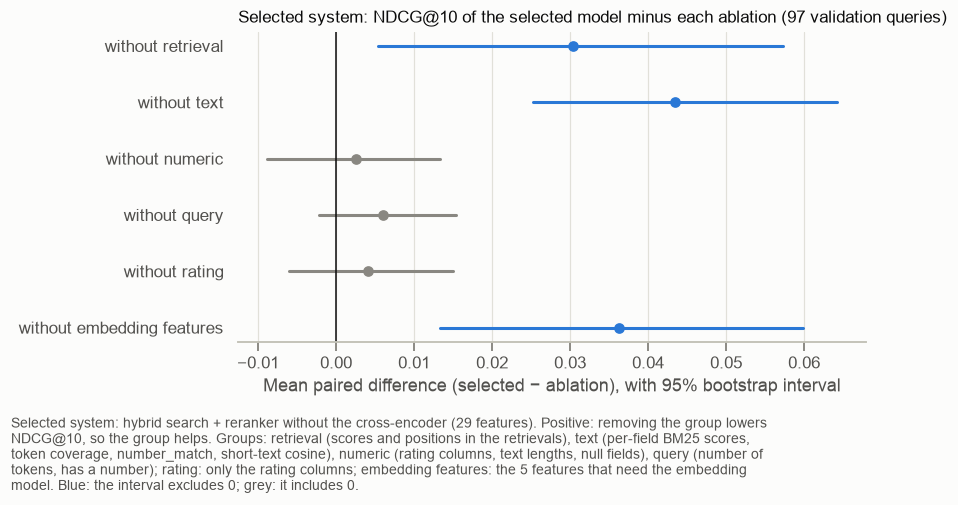

In [23]:
variants = list(selected_ablation_sets)
rows = [selected_ablation_comparisons[variant].loc["ndcg@10"] for variant in variants]
fig, ax = plt.subplots(figsize=(8, 3.8))
plots.difference_plot(ax, variants, [row["difference"] for row in rows], [row["difference_ci_low"] for row in rows],
                      [row["difference_ci_high"] for row in rows])
ax.set_title("Selected system: NDCG@10 of the selected model minus each ablation (97 validation queries)")
ax.set_xlabel("Mean paired difference (selected − ablation), with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Selected system: hybrid search + reranker without the cross-encoder (29 features). Positive: removing the group lowers "
    "NDCG@10, so the group helps. Groups: retrieval (scores and positions in the retrievals), text (per-field BM25 scores, token "
    "coverage, number_match, short-text cosine), numeric (rating columns, text lengths, null fields), query (number of tokens, "
    "has a number); rating: only the rating columns; embedding features: the 5 features that need the embedding model. "
    "Blue: the interval excludes 0; grey: it includes 0."
))
plt.show()


**Resultados**
- **No sistema escolhido, três grupos ajudam, com intervalos que excluem 0:** text +0,043 [0,025; 0,064], features de embedding +0,036 [0,013; 0,060] e retrieval +0,030 [0,005; 0,057].
- **O grupo text pesa mais que no modelo com o cross-encoder** (Etapa 5.3: +0,018 [0,003; 0,034]); retrieval e embedding ficam parecidos (+0,028 e +0,030 na Etapa 5.3).
- **Os grupos numeric e query e as colunas de rating não têm efeito distinguível de 0:** de +0,002 a +0,006, todos com intervalos que incluem 0.
- **No condensed NDCG@10, só retrieval (+0,031 [0,009; 0,053]) e embedding (+0,022 [0,006; 0,039]) ajudam;** o grupo text fica em +0,002 [−0,010; 0,016].

**O que isso implica (nossa interpretação)**
- Sem o cross-encoder, o match de texto por field carrega parte do sinal que o cross-encoder dava. Com os dois no modelo, um compensava a falta do outro na ablation da Etapa 5.3.
- O ganho do grupo text vem sobretudo de trazer ao topo produtos com `label`, como o ganho do reranker inteiro (Etapa 4).

**Limitações**
- As mesmas da Etapa 5.3: um grupo de cada vez, sem novo tuning e sem correção para comparações múltiplas.
- Seção acrescentada depois do test set; ela não muda a seleção.


### 5.4 · Importância das features (gain)

A importância por gain soma, para cada feature, quanto as divisões das árvores que a usam reduziram o erro do treino. É uma descrição do modelo final, não uma medida de quanto a feature melhora o NDCG@10 (isso é a ablation da Etapa 5.3).

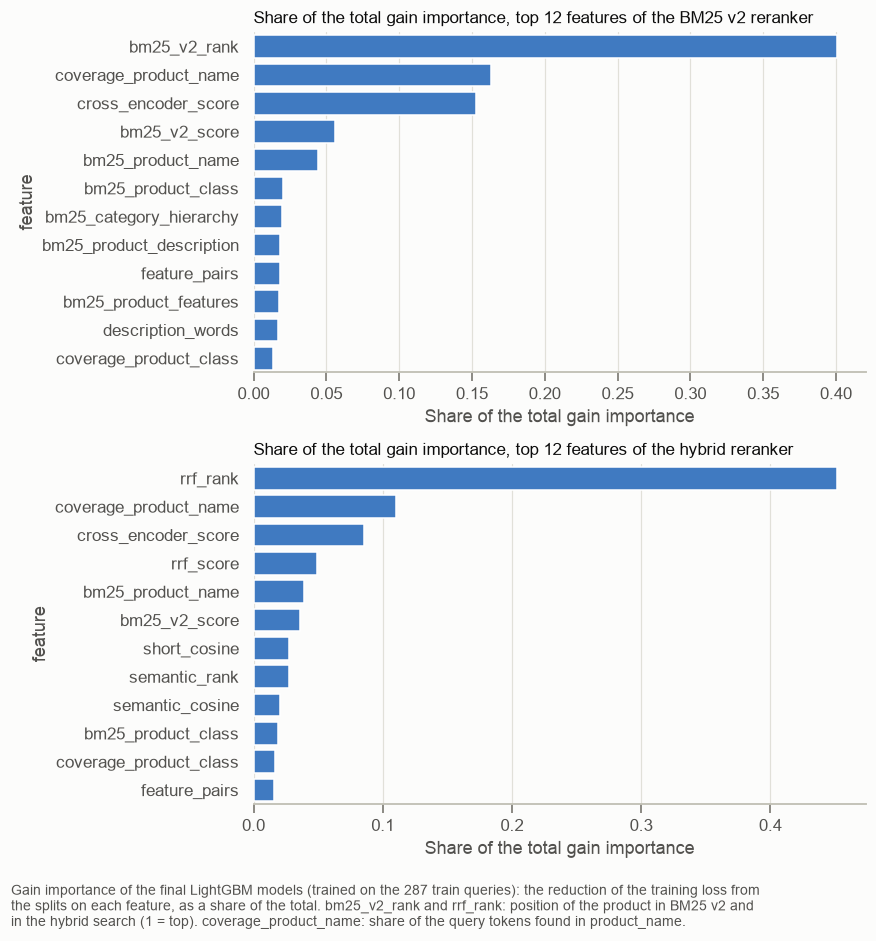

In [24]:
importances = {name: pd.Series(model.booster_.feature_importance("gain"), index=SYSTEM_FEATURES[name]) for name, model in final_models.items()}
importance_shares = {name: (values / values.sum()).sort_values(ascending=False) for name, values in importances.items()}
fig, axes = plt.subplots(2, 1, figsize=(8, 8))
for ax, name in zip(axes, SYSTEMS):
    top = importance_shares[name].head(12)
    sns.barplot(x=top.values, y=top.index, color=plots.SERIES_1, ax=ax)
    ax.set_title(f"Share of the total gain importance, top 12 features of the {name} reranker")
    ax.set_xlabel("Share of the total gain importance")
    ax.set_ylabel("feature")
fig.tight_layout()
plots.add_caption(fig, (
    "Gain importance of the final LightGBM models (trained on the 287 train queries): the reduction of the training loss from the "
    "splits on each feature, as a share of the total. bm25_v2_rank and rrf_rank: position of the product in BM25 v2 and in the "
    "hybrid search (1 = top). coverage_product_name: share of the query tokens found in product_name."
))
plt.show()

**Resultados**
- **A posição no retrieval domina:** `bm25_v2_rank` tem cerca de 40% da importância no BM25 v2 + reranker e `rrf_rank` cerca de 45% no hybrid search + reranker.
- **Seguem `coverage_product_name` e `cross_encoder_score`:** cerca de 16% e 15% (BM25 v2); cerca de 11% e 9% (hybrid).

**O que isso implica (nossa interpretação)**
- O modelo parte da ordem do retrieval e a corrige com sinais de texto. O `cross_encoder_score` é muito usado pelas árvores, mas a ablation (Etapa 5.3) mostra que, sem ele, outras features ocupam o lugar sem perda.

## Etapa 6 · Latência

Medimos, nas 97 queries do validation set, o tempo de uma busca separado em duas partes:
- **retrieval:** a busca dos 200 primeiros (`evaluate.run_system`), nos quatro retrievals (BM25, BM25 v2, semantic search e hybrid search);
- **ranking:** cálculo das features dos 100 primeiros mais a nota do modelo (`reranker.ranking_latency`), com e sem o cross-encoder. O BM25 v2 + reranker não roda o embedding model.

Em todas, 20 buscas de aquecimento antes de medir. Os números mudam a cada execução e dependem da máquina: um CPU de notebook, sem GPU. Por isso a latência não entra na regra de seleção (`docs/EVALUATION.md`).

In [25]:
RETRIEVALS = {"BM25": baseline_index, "BM25 v2": retrievers.v2_index, "semantic search": retrievers.semantic_index,
              "hybrid": retrievers.hybrid_index}
retrieval_latency, retrieval_validation_runs = {}, {}
for name, index in RETRIEVALS.items():
    retrieval_validation_runs[name], retrieval_latency[name] = evaluate.run_system(
        lambda query_text, k, index=index: index.search(query_text, k)["product_id"].tolist(), validation_queries)

ranking_latency = {}
for name in SYSTEMS:
    use_embeddings = name == "hybrid"
    for variant, feature_columns, use_cross_encoder in (("reranker", SYSTEM_FEATURES[name], True),
                                                        ("without cross_encoder", no_cross_encoder[name], False)):
        feature_builder.cross_encoder = cross_encoder if use_cross_encoder else None
        model = final_models[name] if variant == "reranker" else train_final(name, feature_columns)
        ranking_latency[(name, variant)] = reranker.ranking_latency(feature_builder, model, feature_columns, validation_runs[name],
                                                                    validation_queries, use_embeddings=use_embeddings)
feature_builder.cross_encoder = cross_encoder

latency_table = pd.DataFrame({
    f"{name} | {variant}": {
        "retrieval p50": retrieval_latency[name].quantile(0.5), "retrieval p95": retrieval_latency[name].quantile(0.95),
        "ranking p50": ranking_latency[(name, variant)].quantile(0.5), "ranking p95": ranking_latency[(name, variant)].quantile(0.95),
    } for (name, variant) in ranking_latency
}).T.rename_axis("system | ranking")
display(plots.table(pd.DataFrame({name: latency.quantile([0.5, 0.95]).set_axis(["p50", "p95"]) for name, latency in retrieval_latency.items()}).T
                    .rename_axis("retrieval"), "Retrieval latency in milliseconds (top 200), 97 validation queries", precision=1))
plots.table(latency_table, "Latency of one search in milliseconds, retrieval and ranking, 97 validation queries", precision=1,
            note=f"One process on {platform.platform()} ({platform.processor()}), CPU only, after {evaluate.WARMUP_QUERIES} warm-up "
                 "searches. Retrieval: top 200. Ranking: features of the top 100 and the LightGBM score; without the retrieval time.")

,p50,p95
retrieval,,
BM25,0.7,2.9
BM25 v2,0.7,2.9
semantic search,7.5,9.6
hybrid,9.3,12.8


,retrieval p50,retrieval p95,ranking p50,ranking p95
system | ranking,,,,
BM25 v2 | reranker,0.7,2.9,283.0,418.8
BM25 v2 | without cross_encoder,0.7,2.9,6.1,6.7
hybrid | reranker,9.3,12.8,312.6,454.5
hybrid | without cross_encoder,9.3,12.8,24.8,28.9


**Resultados**
- **Na execução salva, o cross-encoder responde por mais de 90% do tempo do ranking:** a mediana do ranking é 283,0 ms com ele e 6,1 ms sem ele no BM25 v2 + reranker, e 312,6 ms e 24,8 ms no hybrid search + reranker. O p95 vai de 418,8 para 6,7 ms e de 454,5 para 28,9 ms.
- **O retrieval é barato perto do ranking com o cross-encoder:** mediana de 0,7 ms (BM25), 0,7 ms (BM25 v2), 7,5 ms (semantic search) e 9,3 ms (hybrid search). No hybrid search + reranker sem o cross-encoder, o ranking (24,8 ms) inclui o embedding da query, calculado de novo para as features.

**O que isso implica (nossa interpretação)**
- Sem o cross-encoder, o ranking cabe em poucas dezenas de milissegundos nesta máquina. Com ele, o custo depende do hardware de produção (uma GPU reduziria o tempo do cross-encoder, o que não medimos).

**Limitações**
- Uma única execução numa única máquina, sem GPU; os números variam de uma execução para outra.
- O retrieval e o ranking são medidos em passes separados; a soma das medianas aproxima, mas não é, a mediana de uma busca completa.

## Etapa 7 · Tabela final, comparação dos sistemas e seleção

### 7.1 · Tabela final do validation set

Todos os sistemas e todas as variantes medidos no validation set, numa única tabela. Há três tipos de linha:
- **sistema:** os cinco sistemas da regra de seleção (BM25, semantic search, hybrid search, BM25 v2 + reranker, hybrid search + reranker), mais a BM25 v2, que é o retrieval do BM25 v2 + reranker;
- **escolhido:** o hybrid search + reranker sem o cross-encoder, pela emenda da regra de seleção (Etapa 7.3);
- **referência:** variantes que respondem a uma pergunta das Etapas 4 e 5 e não entram na seleção.

As ablations por grupo de features estão na Etapa 5.3. A latência é a da execução salva da Etapa 6; "–" quando não foi medida.

In [26]:
FINAL_ROWS = {
    # name: (kind, per-query metrics, retrieval of the latency, ranking latency key)
    "BM25": ("system", metrics.evaluate_run(retrieval_validation_runs["BM25"], labels_by_query, metrics.SENSITIVITY_NDCG_CUTOFFS), "BM25", None),
    "BM25 v2": ("system", validation_per_query[("BM25 v2", "retrieval order")], "BM25 v2", None),
    "semantic search": ("system", metrics.evaluate_run(retrieval_validation_runs["semantic search"], labels_by_query,
                                                       metrics.SENSITIVITY_NDCG_CUTOFFS), "semantic search", None),
    "hybrid search": ("system", validation_per_query[("hybrid", "retrieval order")], "hybrid", None),
    "BM25 v2 + reranker": ("system", validation_per_query[("BM25 v2", "reranker")], "BM25 v2", ("BM25 v2", "reranker")),
    "BM25 v2 + reranker without cross-encoder": ("reference", validation_per_query[("BM25 v2", "without cross_encoder")], "BM25 v2",
                                                 ("BM25 v2", "without cross_encoder")),
    "BM25 v2 + reranker with embedding features": ("reference", validation_per_query[("BM25 v2", "with embedding features")], "BM25 v2", None),
    "BM25 v2 + pointwise": ("reference", validation_per_query[("BM25 v2", "pointwise")], "BM25 v2", None),
    "BM25 v2 + cross-encoder alone": ("reference", validation_per_query[("BM25 v2", "cross-encoder alone")], "BM25 v2", None),
    "hybrid search + reranker": ("system", validation_per_query[("hybrid", "reranker")], "hybrid", ("hybrid", "reranker")),
    "hybrid search + reranker without cross-encoder": ("selected", validation_per_query[("hybrid", "without cross_encoder")], "hybrid",
                                                       ("hybrid", "without cross_encoder")),
    "hybrid search + pointwise": ("reference", validation_per_query[("hybrid", "pointwise")], "hybrid", None),
    "hybrid search + cross-encoder alone": ("reference", validation_per_query[("hybrid", "cross-encoder alone")], "hybrid", None),
}
MEAN_COLUMNS = ["condensed_ndcg@10", "mrr@10", "capped_recall@100", "capped_recall@100_exact_partial", "judged@10", "ndcg@5", "ndcg@15"]


def milliseconds(series, quantile):
    return "–" if series is None else f"{series.quantile(quantile):.1f}"


final_table = pd.DataFrame({
    name: {
        "kind": kind,
        "NDCG@10": evaluate.format_ci(*evaluate.summary_table(per_query[["ndcg@10"]]).loc["ndcg@10", ["mean", "ci_low", "ci_high"]]),
        **{column: f"{per_query[column].mean():.3f}" for column in MEAN_COLUMNS},
        "retrieval p50 / p95 (ms)": f"{milliseconds(retrieval_latency[retrieval_name], 0.5)} / {milliseconds(retrieval_latency[retrieval_name], 0.95)}",
        "ranking p50 / p95 (ms)": "–" if ranking_key is None else
            f"{milliseconds(ranking_latency[ranking_key], 0.5)} / {milliseconds(ranking_latency[ranking_key], 0.95)}",
    } for name, (kind, per_query, retrieval_name, ranking_key) in FINAL_ROWS.items()
}).T.rename_axis("system or variant")
plots.table(final_table, "Final table: every system and variant on the 97 validation queries", max_text_length=60,
            note="NDCG@10: mean with 95% bootstrap interval; other columns: means. MRR@10 and Capped Recall@100: 77 queries with Exact; "
                 "capped_recall@100_exact_partial: Exact and Partial count as relevant (97 queries). "
                 "Rerankers: LambdaMART (LightGBM) over the top 100 of the retrieval; the BM25 v2 rerankers do not use the embedding model. "
                 "Latency: saved run of Etapa 6, CPU only; ranking excludes the retrieval time; – : not measured.")

,kind,NDCG@10,condensed_ndcg@10,mrr@10,capped_recall@100,capped_recall@100_exact_partial,judged@10,ndcg@5,ndcg@15,retrieval p50 / p95 (ms),ranking p50 / p95 (ms)
system or variant,,,,,,,,,,,
BM25,system,0.620 [0.555; 0.687],0.781,0.610,0.702,0.637,0.756,0.605,0.620,0.7 / 2.9,–
BM25 v2,system,0.653 [0.589; 0.718],0.799,0.661,0.705,0.661,0.782,0.647,0.655,0.7 / 2.9,–
semantic search,system,0.725 [0.668; 0.785],0.836,0.661,0.678,0.660,0.824,0.728,0.717,7.5 / 9.6,–
hybrid search,system,0.747 [0.690; 0.805],0.834,0.681,0.714,0.694,0.854,0.747,0.741,9.3 / 12.8,–
BM25 v2 + reranker,system,0.744 [0.682; 0.802],0.802,0.710,0.705,0.661,0.890,0.745,0.740,0.7 / 2.9,283.0 / 418.8
BM25 v2 + reranker without cross-encoder,reference,0.740 [0.678; 0.800],0.806,0.719,0.705,0.661,0.888,0.737,0.733,0.7 / 2.9,6.1 / 6.7
BM25 v2 + reranker with embedding features,reference,0.767 [0.712; 0.823],0.819,0.721,0.705,0.661,0.900,0.773,0.754,0.7 / 2.9,–
BM25 v2 + pointwise,reference,0.729 [0.665; 0.792],0.789,0.667,0.705,0.661,0.892,0.722,0.729,0.7 / 2.9,–
BM25 v2 + cross-encoder alone,reference,0.718 [0.657; 0.777],0.784,0.700,0.705,0.661,0.876,0.722,0.710,0.7 / 2.9,–


**Resultados**
- **O maior NDCG@10 é o do hybrid search + reranker sem o cross-encoder (0,776),** seguido do hybrid search + reranker (0,772) e do BM25 v2 + reranker com as features de embedding (0,767), que é só uma referência.
- **As linhas com um modelo treinado (LambdaMART ou pointwise) têm judged@10 de 0,888 a 0,900,** contra 0,756 a 0,854 dos retrievals sozinhos e 0,865 e 0,876 do cross-encoder sozinho.
- **No condensed NDCG@10, a hybrid search sozinha (0,834) fica no mesmo nível dos rerankers sobre ela (0,831 e 0,832),** e a maior média é a da semantic search (0,836).
- **O Capped Recall@100 de cada reranker é o do seu retrieval:** 0,705 (BM25 v2) e 0,714 (hybrid search).
- **Com Exact e Partial como relevantes, a hybrid search é a que mais cobre:** Capped Recall@100 de 0,694, contra 0,637 (BM25), 0,661 (BM25 v2) e 0,660 (semantic search). Os rerankers têm o valor do seu retrieval.

**Limitações**
- 97 queries; intervalos de cerca de ±0,05 em cada média de NDCG@10. As comparações entre sistemas usam o paired bootstrap (Etapas 4 e 5), mais preciso que comparar os intervalos das médias.

### 7.2 · Os sistemas lado a lado

Os mesmos números da Etapa 7.1, em gráfico, para os sete sistemas que respondem às perguntas principais: os quatro retrievals, os dois rerankers e o sistema escolhido. Primeiro, cada métrica com o seu intervalo de 95%; depois, o NDCG@10 contra a latência.

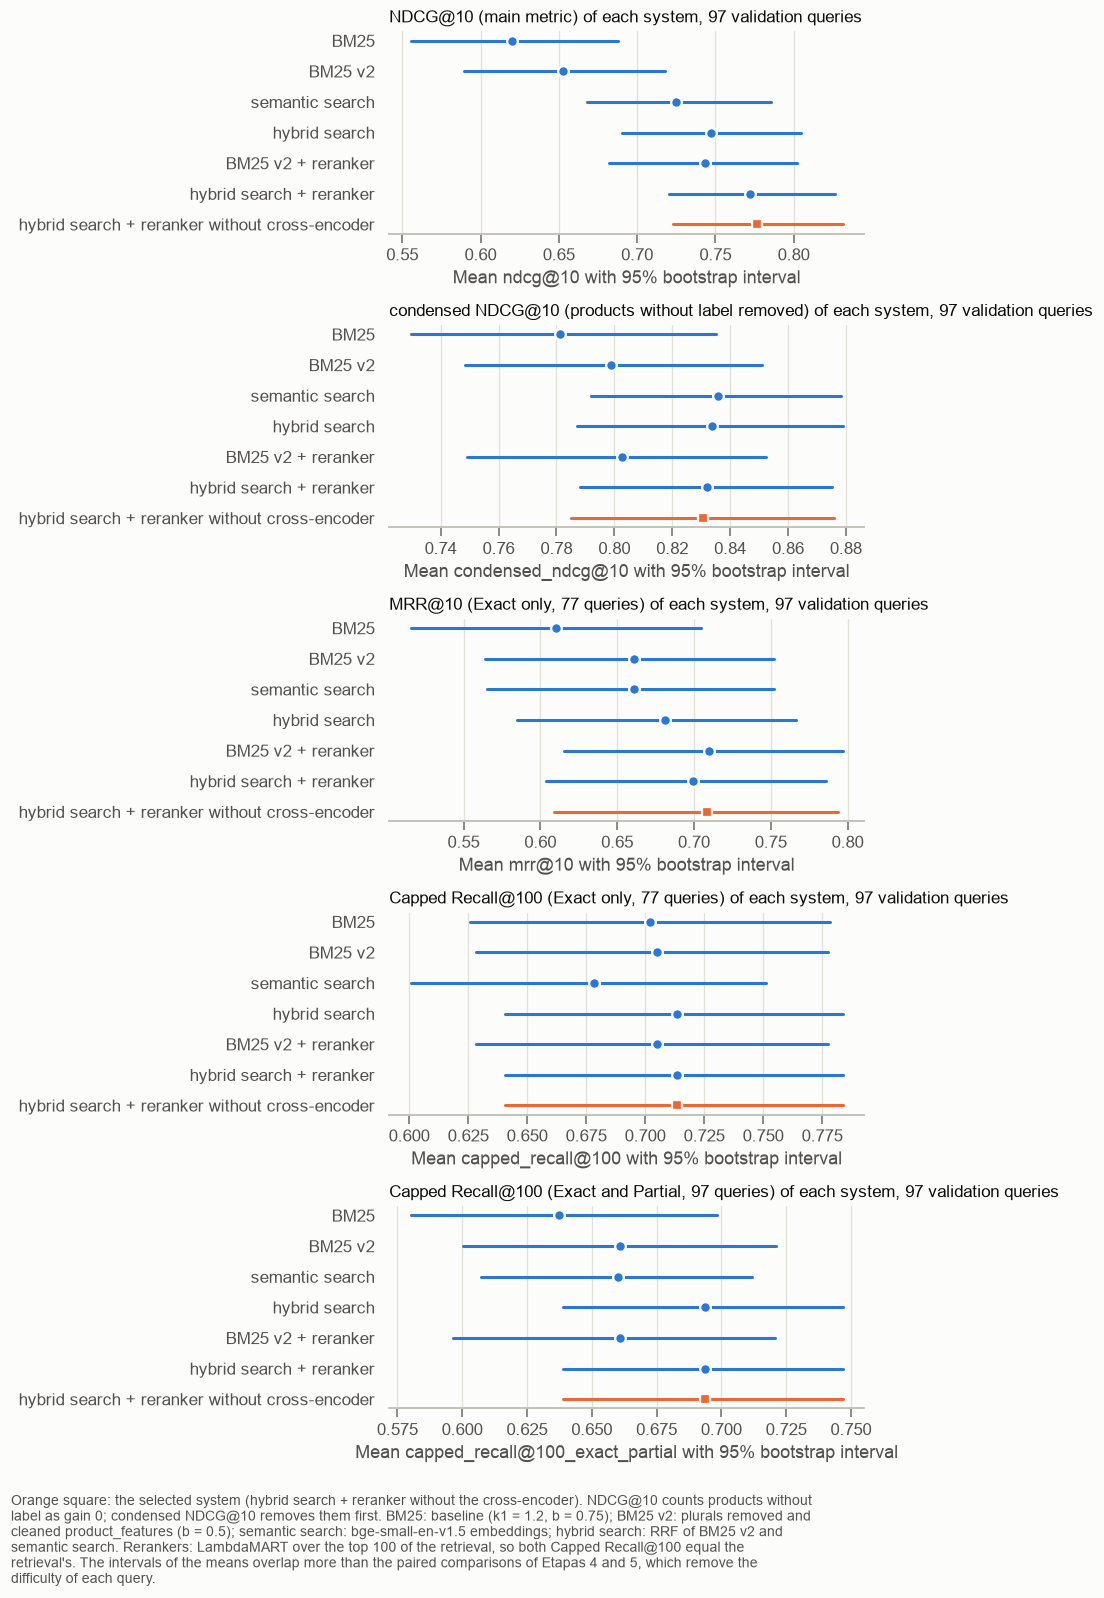

In [27]:
PLOT_SYSTEMS = ["BM25", "BM25 v2", "semantic search", "hybrid search", "BM25 v2 + reranker", "hybrid search + reranker",
                "hybrid search + reranker without cross-encoder"]
SELECTED_SYSTEM = "hybrid search + reranker without cross-encoder"
PLOT_METRICS = {"ndcg@10": "NDCG@10 (main metric)", "condensed_ndcg@10": "condensed NDCG@10 (products without label removed)",
                "mrr@10": "MRR@10 (Exact only, 77 queries)", "capped_recall@100": "Capped Recall@100 (Exact only, 77 queries)",
                "capped_recall@100_exact_partial": "Capped Recall@100 (Exact and Partial, 97 queries)"}
fig, axes = plt.subplots(len(PLOT_METRICS), 1, figsize=(8, 13.5))
for ax, (metric, title) in zip(axes, PLOT_METRICS.items()):
    summaries = [evaluate.summary_table(FINAL_ROWS[name][1][[metric]]).loc[metric] for name in PLOT_SYSTEMS]
    plots.system_interval_plot(ax, PLOT_SYSTEMS, [row["mean"] for row in summaries], [row["ci_low"] for row in summaries],
                               [row["ci_high"] for row in summaries], highlight=SELECTED_SYSTEM)
    ax.set_title(f"{title} of each system, 97 validation queries")
    ax.set_xlabel(f"Mean {metric} with 95% bootstrap interval")
fig.tight_layout()
plots.add_caption(fig, (
    "Orange square: the selected system (hybrid search + reranker without the cross-encoder). NDCG@10 counts products without label "
    "as gain 0; condensed NDCG@10 removes them first. BM25: baseline (k1 = 1.2, b = 0.75); BM25 v2: plurals removed and cleaned "
    "product_features (b = 0.5); semantic search: bge-small-en-v1.5 embeddings; hybrid search: RRF of BM25 v2 and semantic search. "
    "Rerankers: LambdaMART over the top 100 of the retrieval, so both Capped Recall@100 equal the retrieval's. The intervals of the "
    "means overlap more than the paired comparisons of Etapas 4 and 5, which remove the difficulty of each query."
))
plt.show()

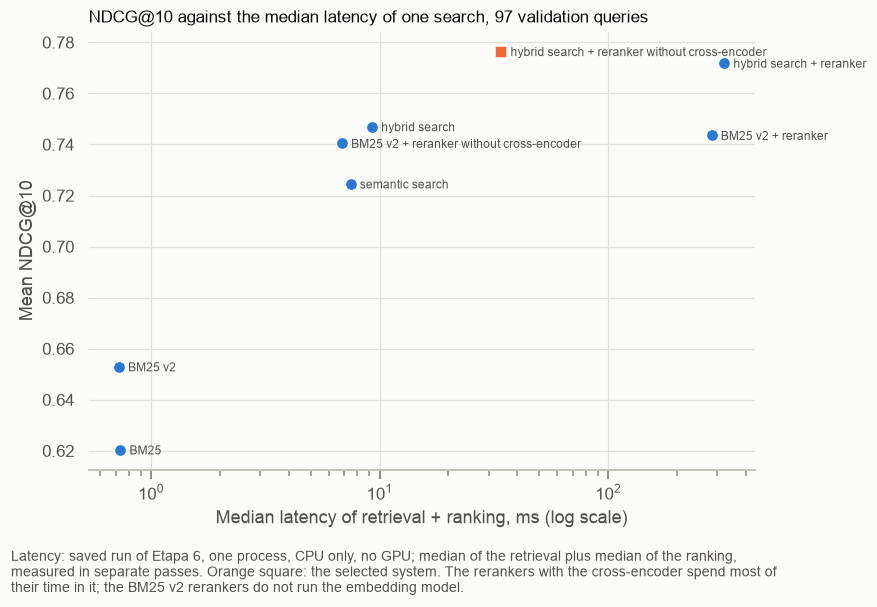

In [28]:
LATENCY_SYSTEMS = {name: row for name, row in FINAL_ROWS.items() if row[0] != "reference" or row[3] is not None}
latency_points = pd.DataFrame({
    name: {"ndcg@10": per_query["ndcg@10"].mean(),
           "total p50 (ms)": retrieval_latency[retrieval_name].quantile(0.5)
           + (0.0 if ranking_key is None else ranking_latency[ranking_key].quantile(0.5)),
           "kind": kind}
    for name, (kind, per_query, retrieval_name, ranking_key) in LATENCY_SYSTEMS.items()
}).T
fig, ax = plt.subplots(figsize=(8, 5))
for name, row in latency_points.iterrows():
    is_selected = name == SELECTED_SYSTEM
    ax.plot(row["total p50 (ms)"], row["ndcg@10"], marker="s" if is_selected else "o", markersize=8, linestyle="none",
            color=plots.SERIES_2 if is_selected else plots.SERIES_1, markeredgecolor=plots.SURFACE)
    ax.annotate(name, (row["total p50 (ms)"], row["ndcg@10"]), xytext=(6, -3), textcoords="offset points", fontsize=8,
                color=plots.SECONDARY_INK)
ax.set_xscale("log")
ax.set_title("NDCG@10 against the median latency of one search, 97 validation queries")
ax.set_xlabel("Median latency of retrieval + ranking, ms (log scale)")
ax.set_ylabel("Mean NDCG@10")
fig.tight_layout()
plots.add_caption(fig, (
    "Latency: saved run of Etapa 6, one process, CPU only, no GPU; median of the retrieval plus median of the ranking, measured in "
    "separate passes. Orange square: the selected system. The rerankers with the cross-encoder spend most of their time in it; "
    "the BM25 v2 rerankers do not run the embedding model."
))
plt.show()

**Resultados**
- **No NDCG@10, as médias dos sistemas com reranker e da hybrid search ficam acima das médias da BM25, da BM25 v2 e da semantic search;** no condensed NDCG@10 e no MRR@10, os intervalos dos sete sistemas se sobrepõem.
- **No gráfico de latência, as versões com o cross-encoder ficam perto de 300 ms por busca (mediana de retrieval + ranking: 283,7 ms no BM25 v2 + reranker e 321,9 ms no hybrid search + reranker);** o sistema escolhido fica em 34,1 ms, com o maior NDCG@10 (0,776). Os retrievals sozinhos ficam entre 0,7 e 9,3 ms.

**O que isso implica (nossa interpretação)**
- Entre os sistemas medidos, o escolhido é o de maior NDCG@10 sem pagar o custo do cross-encoder. Num hardware de produção com GPU, a distância de latência das versões com cross-encoder deve diminuir, o que não medimos.

### 7.3 · A seleção final

A regra registrada no `docs/EVALUATION.md` é aplicada uma única vez, depois de todos os sistemas medidos no validation set: fica o sistema de maior NDCG@10 médio, a não ser que o intervalo de 95% do paired bootstrap da diferença para um sistema mais simples inclua 0; nesse caso, fica o mais simples. Ordem de simplicidade: BM25 < semantic search < hybrid search < BM25 v2 + reranker < hybrid search + reranker.

**Emenda, feita depois de ver o validation set do reranker:** o mesmo princípio vale para os componentes de um sistema. Se o sistema de maior NDCG@10 tem um componente opcional cuja retirada dá uma diferença com intervalo que inclui 0, fica a versão sem ele. Motivo: a regra original deixava de fora o cross-encoder, que entrou como grupo de features e foi medido só como ablation; deveríamos ter exigido que ele se justificasse na seleção.

In [29]:
SELECTION_SYSTEMS = ["BM25", "semantic search", "hybrid search", "BM25 v2 + reranker", "hybrid search + reranker"]
best_system = max(SELECTION_SYSTEMS, key=lambda name: FINAL_ROWS[name][1]["ndcg@10"].mean())
selection_rows = {}
for name in SELECTION_SYSTEMS:
    per_query = FINAL_ROWS[name][1]
    selection_rows[name] = {
        "NDCG@10": evaluate.format_ci(*evaluate.summary_table(per_query[["ndcg@10"]]).loc["ndcg@10", ["mean", "ci_low", "ci_high"]]),
        f"{best_system} − system": "–" if name == best_system else evaluate.compare_systems(
            FINAL_ROWS[best_system][1][["ndcg@10"]], per_query[["ndcg@10"]], ["ndcg@10"], name_a="a", name_b="b").loc["ndcg@10", "difference_ci"],
    }
amendment = evaluate.compare_systems(FINAL_ROWS[best_system][1][["ndcg@10"]], FINAL_ROWS[SELECTED_SYSTEM][1][["ndcg@10"]], ["ndcg@10"],
                                     name_a="a", name_b="b").loc["ndcg@10", "difference_ci"]
display(plots.table(pd.DataFrame(selection_rows).T.rename_axis("system (simplest first)"),
                    "Selection rule: NDCG@10 of the five systems and the difference from the best, 97 validation queries",
                    note="Mean with 95% bootstrap interval; difference: mean paired difference with 95% paired bootstrap interval. "
                         "The rule keeps the best system unless the interval of its difference to a simpler system contains 0."))
print(f"best by the rule: {best_system}")
print(f"amendment: {best_system} − {SELECTED_SYSTEM} = {amendment} (NDCG@10)")

,NDCG@10,hybrid search + reranker − system
system (simplest first),,
BM25,0.620 [0.555; 0.687],0.151 [0.115; 0.188]
semantic search,0.725 [0.668; 0.785],0.047 [0.021; 0.075]
hybrid search,0.747 [0.690; 0.805],0.025 [0.009; 0.043]
BM25 v2 + reranker,0.744 [0.682; 0.802],0.028 [0.010; 0.048]
hybrid search + reranker,0.772 [0.720; 0.827],–


best by the rule: hybrid search + reranker
amendment: hybrid search + reranker − hybrid search + reranker without cross-encoder = -0.005 [-0.015; 0.006] (NDCG@10)


**Resultados**
- **Pela regra, fica o hybrid search + reranker:** o maior NDCG@10 dos cinco sistemas (0,772), com diferenças que excluem 0 para todos os mais simples: +0,151 [0,115; 0,188] sobre a BM25, +0,047 [0,021; 0,075] sobre a semantic search, +0,025 [0,009; 0,043] sobre a hybrid search e +0,028 [0,010; 0,048] sobre o BM25 v2 + reranker.
- **Pela emenda, fica a versão sem o cross-encoder:** a diferença do hybrid search + reranker para ela é −0,005 [−0,015; 0,006].

**O que isso implica (nossa interpretação)**
- O sistema escolhido para o test set é o **hybrid search + reranker sem o cross-encoder**. O test set roda também o hybrid search + reranker com o cross-encoder, só como resultado reportado.
- O ganho do reranker sobre a hybrid search vem de trazer ao topo produtos com `label` (Etapa 4.1), em parte real e em parte efeito do pooling bias (Etapa 3.3). A nota técnica precisa mostrar o condensed NDCG@10 ao lado.

**Suposições**
- A emenda supõe que dois sistemas cuja diferença de NDCG@10 no validation set não se distingue de 0 também não diferem em produção, e que o mais barato é preferível. Se o cross-encoder ajudar em queries que o validation set não representa, perdemos esse ganho.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Hybrid search + reranker sem o cross-encoder vai ao test set (regra emendada) | decidida, registrada no `docs/EVALUATION.md` antes do test set | a regra à risca, com o cross-encoder; escolher pelo condensed NDCG@10, em que a hybrid search sozinha não se distingue dos rerankers |
| O test set roda os cinco sistemas da regra e o hybrid search + reranker com o cross-encoder | decidida | rodar só o sistema escolhido |

### 7.4 · Os modelos salvos

Os modelos finais ficam em `models/`, gerados por `uv run python -m wands_search.train_reranker` com as combinações da Etapa 3.1 (`reranker.CHOSEN_COMBINATIONS`) e o train set. Cada modelo tem um arquivo do LightGBM (`.txt`) e um de metadados (`.json`: retrieval, features na ordem, combinação, versões). Aqui conferimos que cada modelo salvo dá, nos candidates do validation set, as mesmas notas do modelo treinado neste notebook.

In [30]:
NOTEBOOK_MODELS = {
    "bm25_v2_reranker": final_models["BM25 v2"],
    "bm25_v2_reranker_no_cross_encoder": train_final("BM25 v2", no_cross_encoder["BM25 v2"]),
    "hybrid_reranker": final_models["hybrid"],
    "hybrid_reranker_no_cross_encoder": train_final("hybrid", no_cross_encoder["hybrid"]),
}
saved_rows = {}
for name, notebook_model in NOTEBOOK_MODELS.items():
    booster, metadata = reranker.load_model(name)
    retrieval_name = metadata["retrieval"]
    columns = metadata["feature_columns"]
    difference = np.abs(reranker.predict(booster, validation_tables[retrieval_name], columns)
                        - reranker.predict(notebook_model, validation_tables[retrieval_name], columns)).max()
    saved_rows[name] = {"retrieval": retrieval_name, "features": len(columns), "selected": metadata["selected"],
                        "trees": metadata["combination"]["n_estimators"], "max |score difference|": f"{difference:.2e}"}
plots.table(pd.DataFrame(saved_rows).T.rename_axis("saved model"),
            "Saved models in models/ and the largest score difference from the models trained in this notebook (validation candidates)",
            precision=0, note="Score difference: absolute difference between the scores of the saved model and of the notebook model on "
                              "every validation candidate of its retrieval; 0 means the saved model reproduces this notebook.")

,retrieval,features,selected,trees,max |score difference|
saved model,,,,,
bm25_v2_reranker,BM25 v2,25,False,100,0.00e+00
bm25_v2_reranker_no_cross_encoder,BM25 v2,24,False,100,0.00e+00
hybrid_reranker,hybrid,30,False,100,0.00e+00
hybrid_reranker_no_cross_encoder,hybrid,29,True,100,0.00e+00


**Resultados**
- **Os quatro modelos salvos reproduzem os modelos deste notebook:** a maior diferença de score, em todos os candidates do validation set, é 0 nos quatro.

**Escolhas e alternativas**

| Escolha | Status | Alternativas |
|---|---|---|
| Modelos salvos no repositório (`models/`, texto do LightGBM com metadados em JSON), treinados por um script | decidida | salvar com `pickle` ou `joblib` (depende da versão do Python e das bibliotecas); treinar na hora da busca |

## Próximo passo: o test set

O sistema escolhido na Etapa 7.3 e as seis linhas registradas no `docs/EVALUATION.md` ("Seleção e teste") rodam no test set uma única vez, em `06_test_set.ipynb`, com os modelos salvos em `models/`. Nada deste notebook usa o test set.